In [1]:
import os
import torch
from botorch import fit_gpytorch_mll
import botorch_tool
import copy
from botorch.sampling.normal import SobolQMCNormalSampler
from botorch.utils.transforms import unnormalize, normalize, standardize
import numpy as np 
import pandas as pd
import json 
from matplotlib import pyplot as plt 
import pickle
from botorch.utils.transforms import standardize
from botorch.models.transforms.outcome import Standardize
from copy import copy 

torch.set_default_dtype(torch.float64)

tkwargs = {"dtype": torch.double,
           "device": torch.device("cuda" if torch.cuda.is_available() else "cpu")}

BATCH_NUM = 0

In [2]:
exp_data = []
for BATCH_NUM_tmp in range(BATCH_NUM+1):
    with open(f"./all_experiment_{BATCH_NUM_tmp}.json", "r") as f:
        exp_data.append(pd.DataFrame(json.load(f)))
        
exp_data = pd.concat(exp_data).sort_values(by=["substance1", "substance2", "volume1"]).reset_index(drop=True)

if not (exp_data.index.astype("int") == np.arange(len(exp_data))).all():
    raise ValueError("the index of the expeirments is not right")

# add noise from Pt experiments
exp_data["variance_S"] = exp_data["variance_S"] + 1.6
exp_data["variance_current"] = exp_data["variance_current"] + 198.53163497959181

In [3]:
exp_data

,substance1,substance2,volume1,volume2,mean_S,variance_S,mean_current,variance_current
0,Ag,Al,3.84,16.16,4.418421,1.602929,54.172955,198.572878
1,Ag,Al,9.24,10.76,4.419926,1.604053,53.953856,198.554116
2,Ag,Al,10.84,9.16,4.589309,1.604731,52.633539,198.553120
3,Ag,Al,16.72,3.28,4.553979,1.635104,54.434124,198.630982
4,Ag,Cr,4.65,15.35,4.942271,1.620578,70.278648,198.584110
...,...,...,...,...,...,...,...,...
539,Y,Zn,17.79,2.21,7.689648,1.904846,19.997663,198.613740
540,Zn,Mo,2.65,17.35,4.420998,1.627072,27.444124,198.545448
541,Zn,Mo,5.72,14.28,5.126487,1.618787,42.474775,198.533840
542,Zn,Mo,10.06,9.94,5.530497,1.622813,31.290317,198.547851


In [4]:
# standarization of the data
std_scaler = Standardize(m = 1)

# mass data 
mean_S, variance_S = std_scaler(
    torch.tensor(exp_data["mean_S"].values.reshape(-1,1)), 
    torch.tensor(exp_data["variance_S"].values.reshape(-1,1)))
exp_data["mean_S"] = copy(mean_S).numpy()
exp_data["variance_S"] = copy(variance_S).numpy()

# current data 
mean_current, variance_current = std_scaler(
    torch.tensor(exp_data["mean_current"].values.reshape(-1,1)), 
    torch.tensor(exp_data["variance_current"].values.reshape(-1,1)))
exp_data["mean_current"] = copy(mean_current).numpy()
exp_data["variance_current"] = copy(variance_current).numpy()

print(exp_data["mean_S"].mean())
print(exp_data["mean_S"].var())

print(exp_data["mean_current"].mean())
print(exp_data["mean_current"].var())

exp_data

2.612289469706251e-16
0.9999999999999993
-2.285753285992969e-16
0.9999999999999998


,substance1,substance2,volume1,volume2,mean_S,variance_S,mean_current,variance_current
0,Ag,Al,3.84,16.16,-1.473729,0.335197,-0.260598,0.139806
1,Ag,Al,9.24,10.76,-1.473041,0.335432,-0.266411,0.139793
2,Ag,Al,10.84,9.16,-1.395583,0.335573,-0.301444,0.139792
3,Ag,Al,16.72,3.28,-1.411739,0.341925,-0.253668,0.139847
4,Ag,Cr,4.65,15.35,-1.234177,0.338887,0.166752,0.139814
...,...,...,...,...,...,...,...,...
539,Y,Zn,17.79,2.21,0.022174,0.398332,-1.167406,0.139835
540,Zn,Mo,2.65,17.35,-1.472550,0.340245,-0.969821,0.139787
541,Zn,Mo,5.72,14.28,-1.149937,0.338513,-0.570998,0.139779
542,Zn,Mo,10.06,9.94,-0.965186,0.339355,-0.867766,0.139789


In [5]:
metal_combo_original = np.concatenate((exp_data["substance1"].values.reshape(-1,1), 
                                       exp_data["substance2"].values.reshape(-1,1)), axis = 1).astype("str")
metal_combo = np.unique(metal_combo_original, axis = 0)
len(metal_combo)

136

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([5.3109]), std = tensor([0.0096])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([5.7346]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


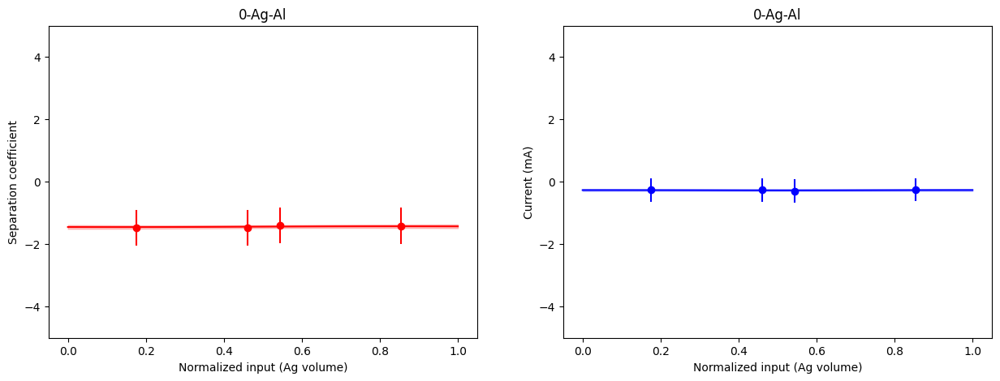

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.7553]), std = tensor([0.0050])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([3.1860]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


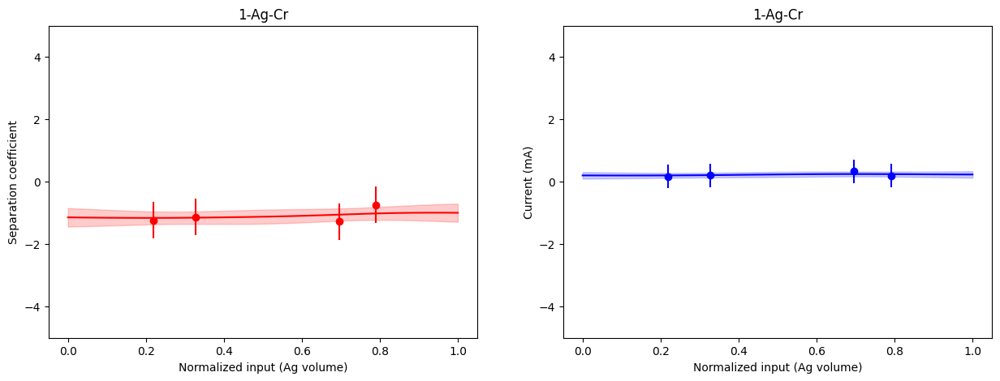

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.7467]), std = tensor([0.0957])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.0345]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


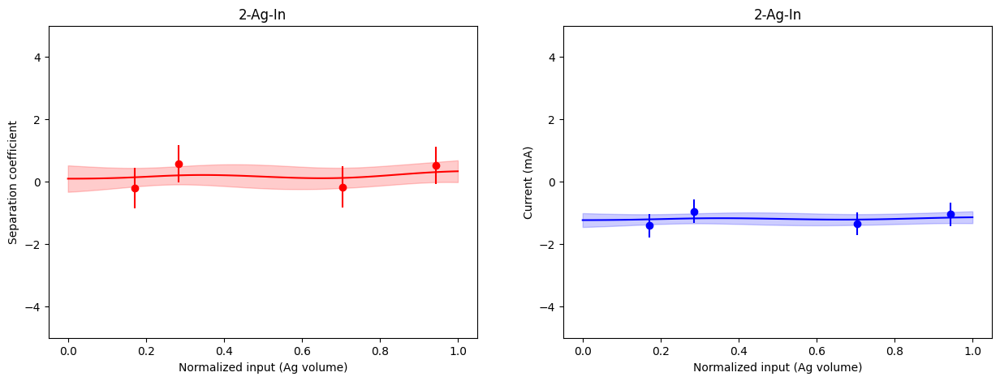

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([5.9569]), std = tensor([0.0342])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.7917]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


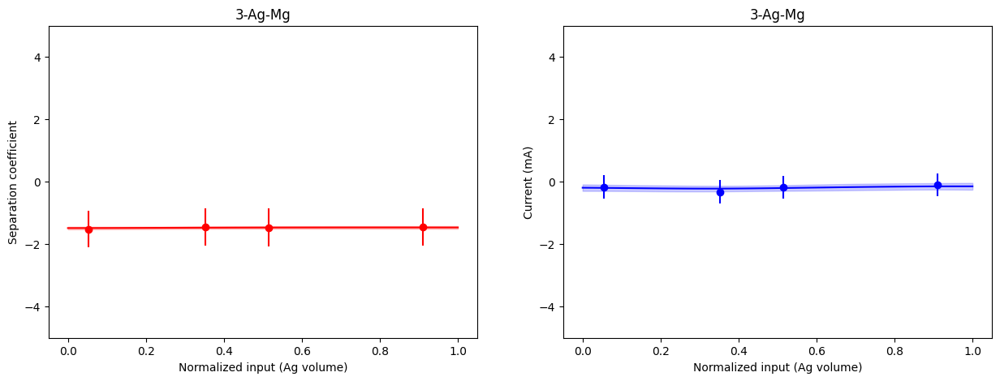

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.8662]), std = tensor([0.0159])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.7507]), std = tensor([0.0004])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


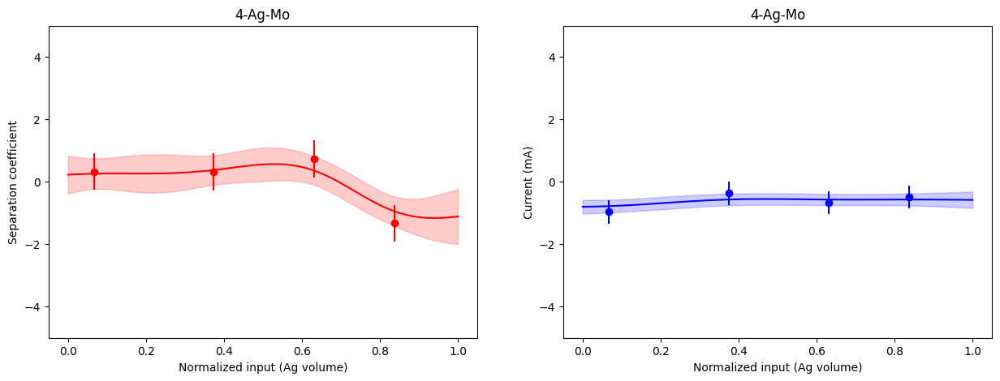

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([7.6849]), std = tensor([0.0326])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([3.9194]), std = tensor([5.1751e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


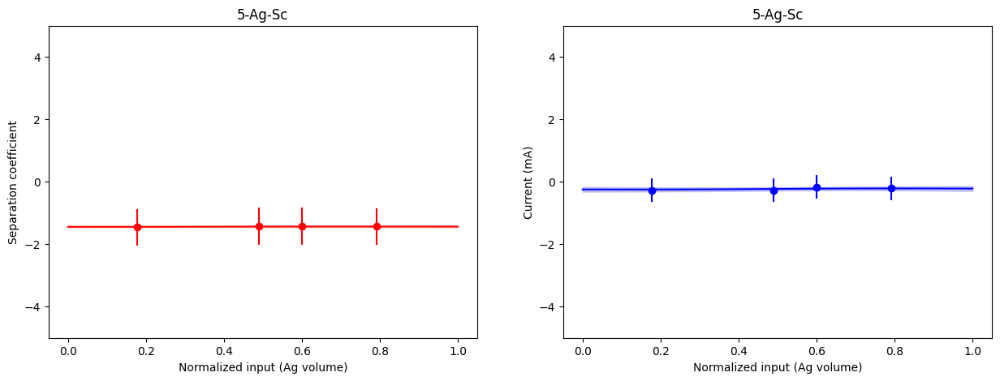

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([5.7014]), std = tensor([0.0350])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.7884]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


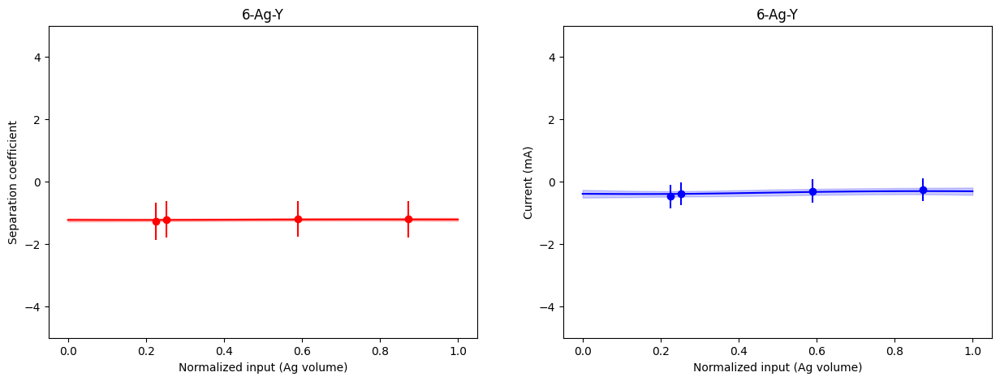

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([3.7569]), std = tensor([0.0163])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([5.0004]), std = tensor([0.0001])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


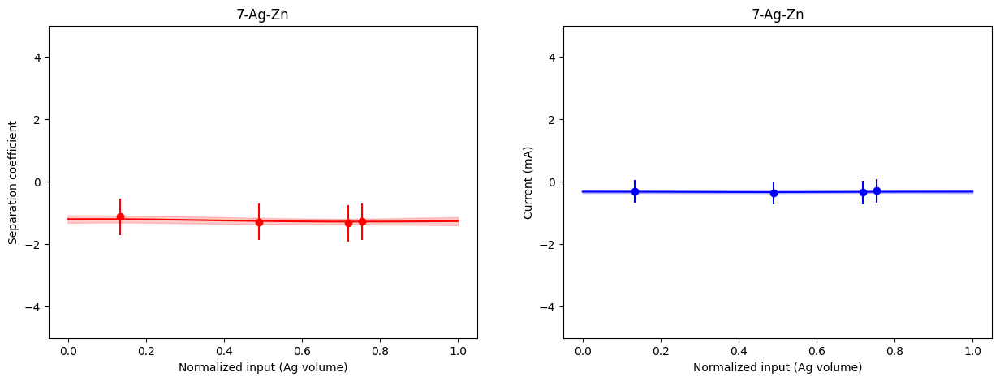

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.9814]), std = tensor([0.0229])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([4.7171]), std = tensor([4.8059e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


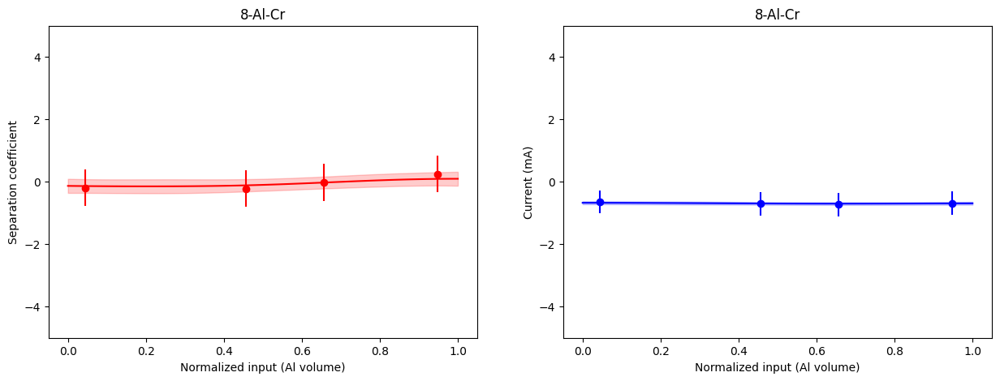

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-2.1723]), std = tensor([0.0323])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.9253]), std = tensor([0.0003])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


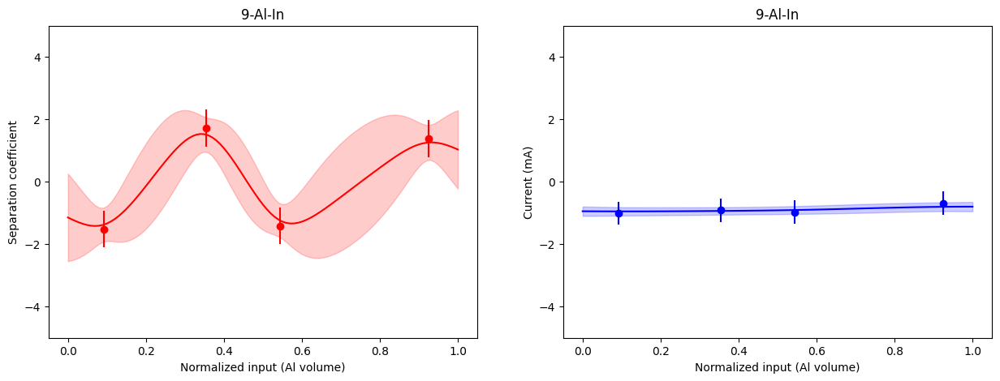

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.0398]), std = tensor([0.0381])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.9649]), std = tensor([0.0004])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


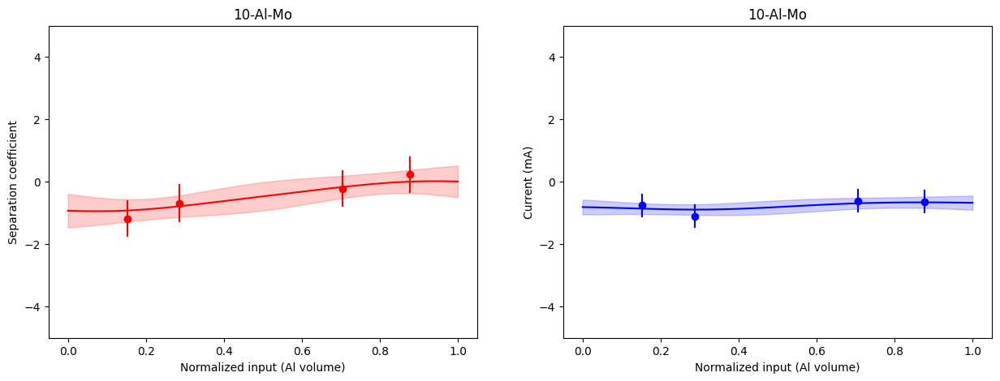

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.2643]), std = tensor([0.1257])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.0656]), std = tensor([0.0001])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


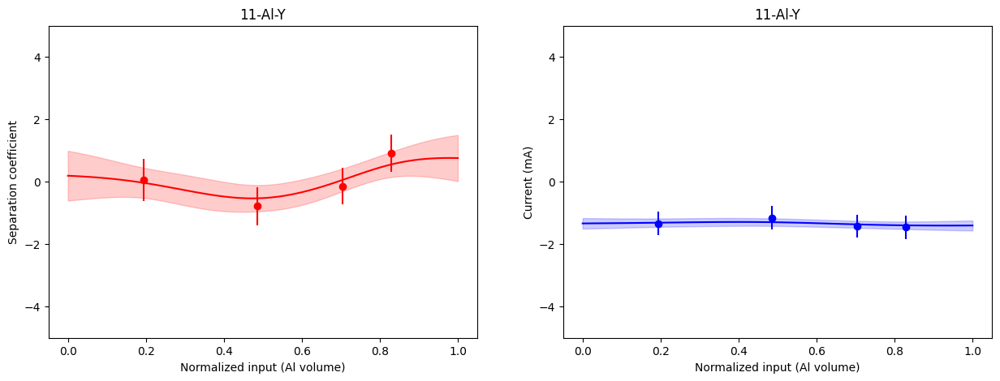

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.9478]), std = tensor([0.1169])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([4.1703]), std = tensor([1.3366e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


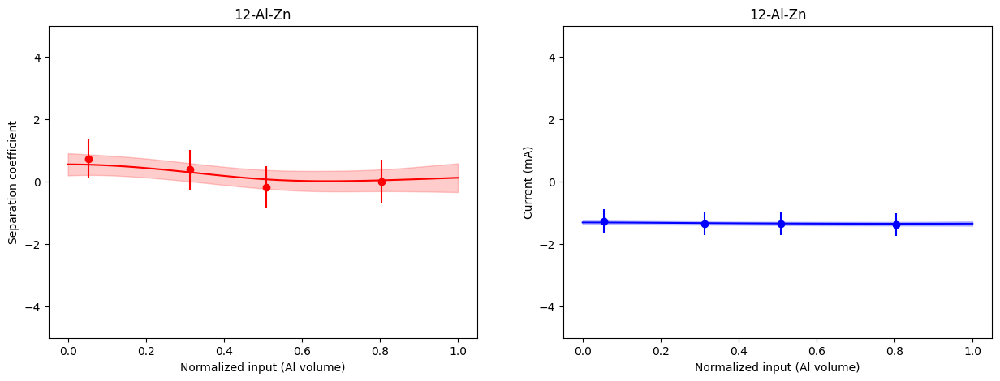

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([3.0239]), std = tensor([0.0512])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.6421]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


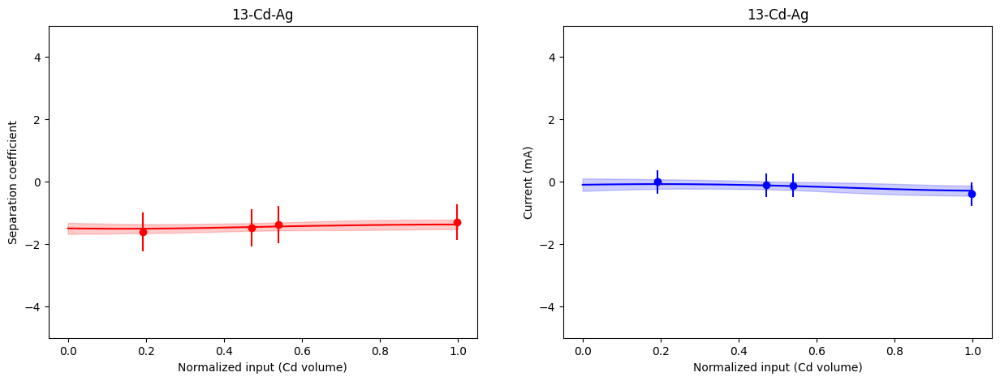

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([3.5585]), std = tensor([0.1363])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.8652]), std = tensor([4.4381e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


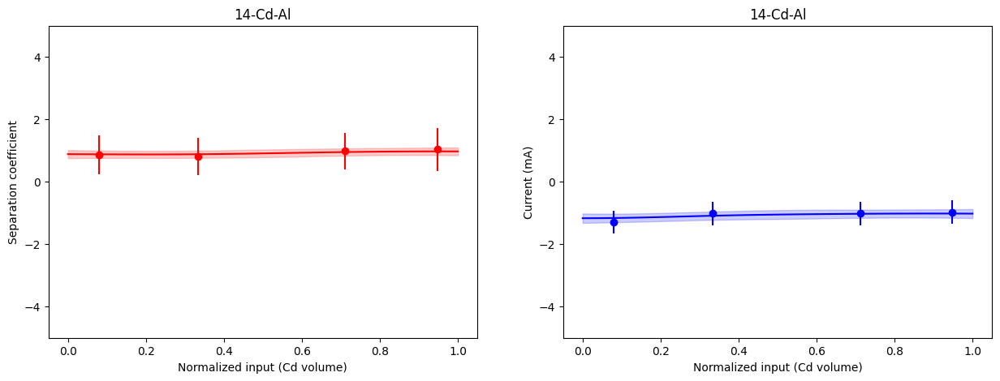

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.7590]), std = tensor([0.0650])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.3068]), std = tensor([0.0001])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


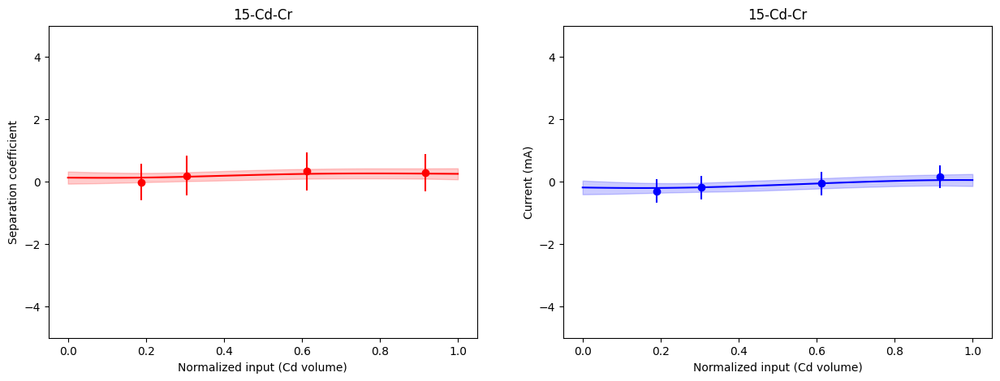

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.8575]), std = tensor([0.3733])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.8530]), std = tensor([0.0001])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


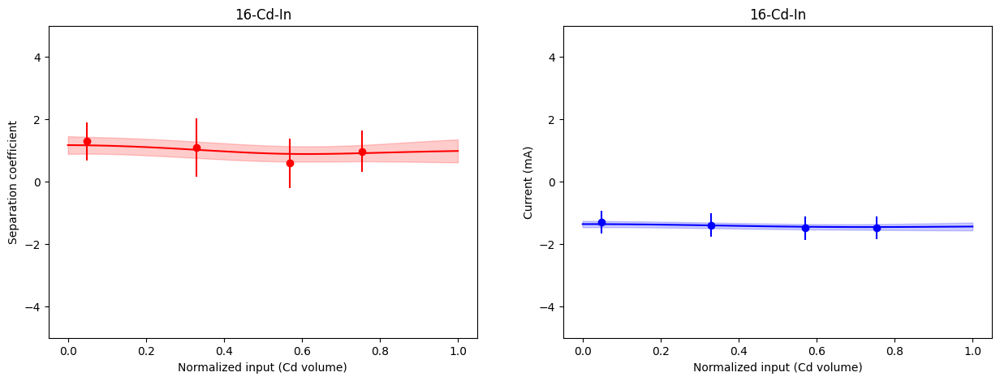

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.6064]), std = tensor([0.1091])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.6137]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


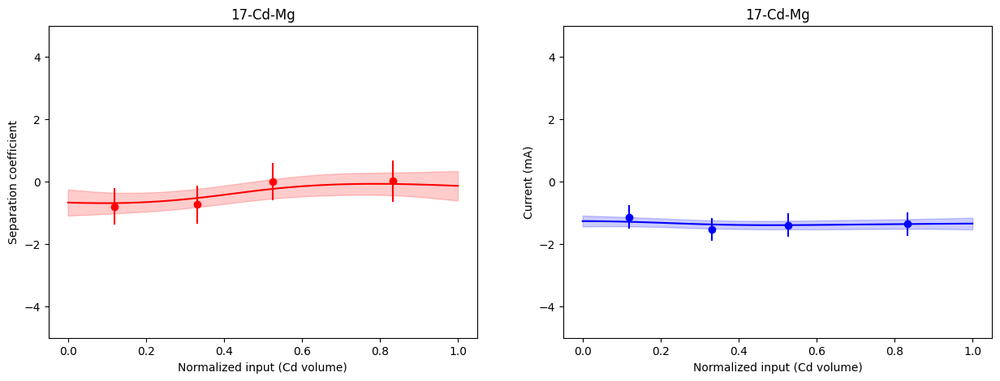

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.9391]), std = tensor([0.0421])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.3210]), std = tensor([3.7292e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


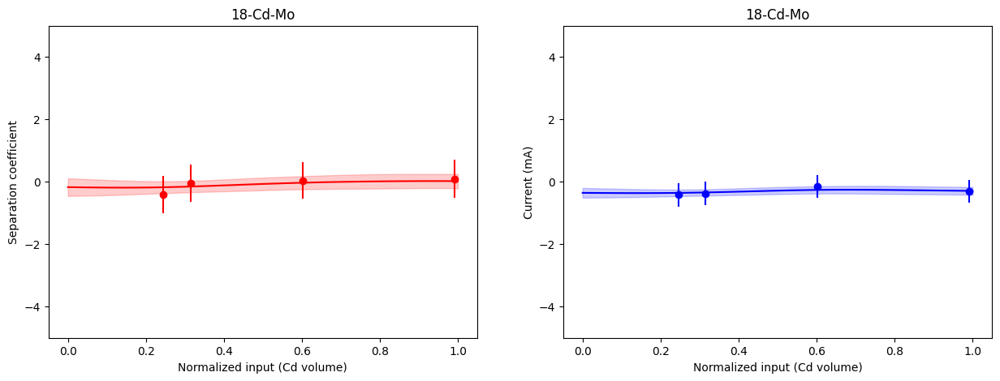

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.6066]), std = tensor([0.0294])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.9423]), std = tensor([0.0008])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


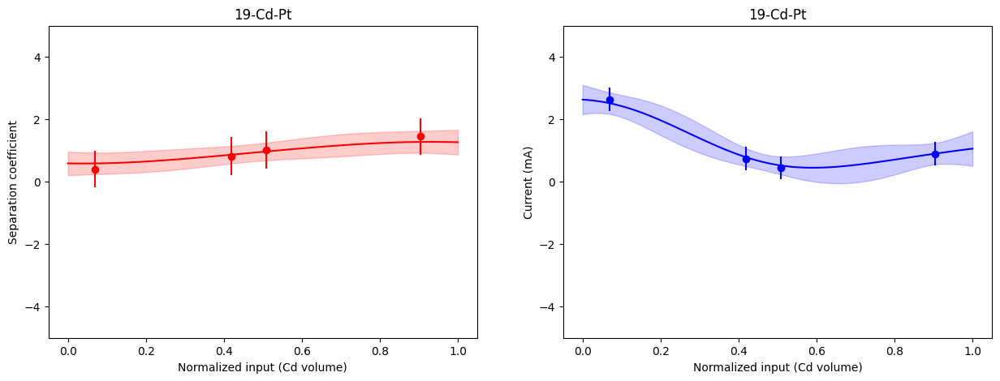

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([6.7900]), std = tensor([0.0532])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.2240]), std = tensor([2.9930e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


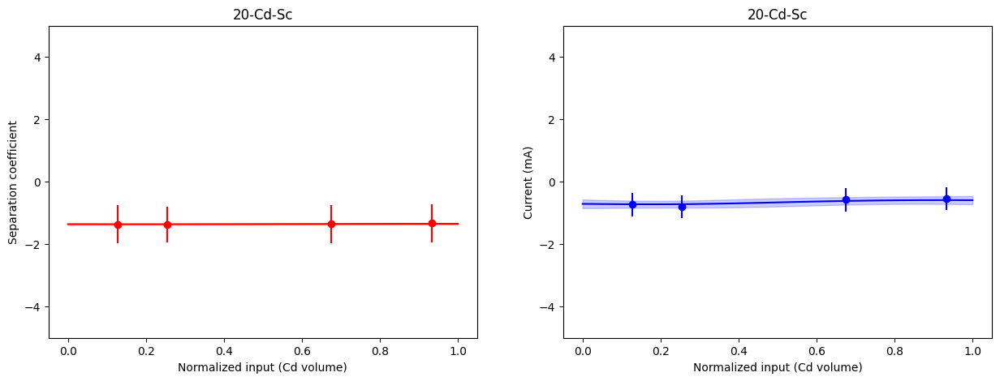

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.5088]), std = tensor([0.0105])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.3745]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


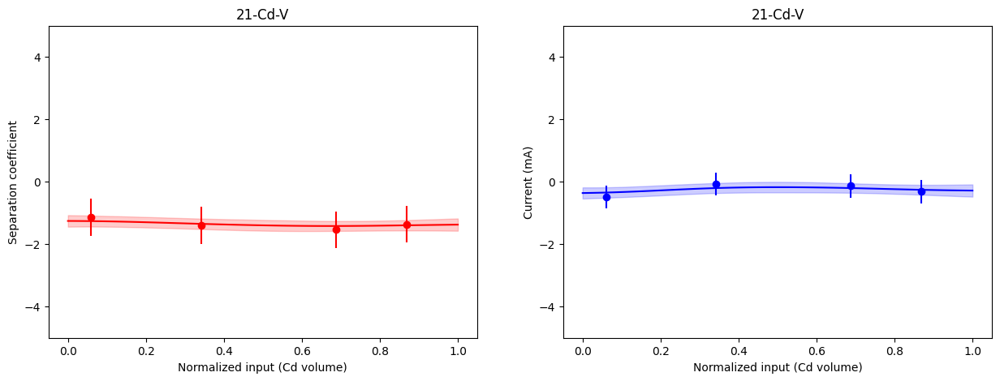

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.6124]), std = tensor([0.1420])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([4.3044]), std = tensor([4.5436e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


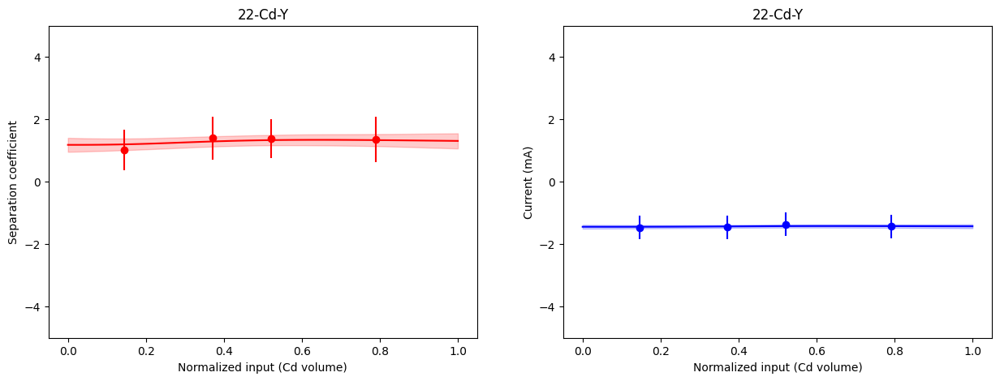

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.8221]), std = tensor([0.1193])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.3634]), std = tensor([0.0004])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


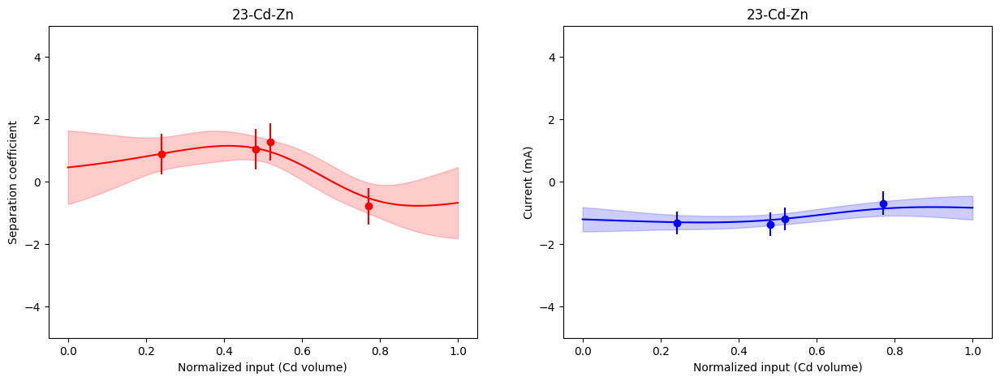

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.8167]), std = tensor([0.0484])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.2035]), std = tensor([0.0023])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


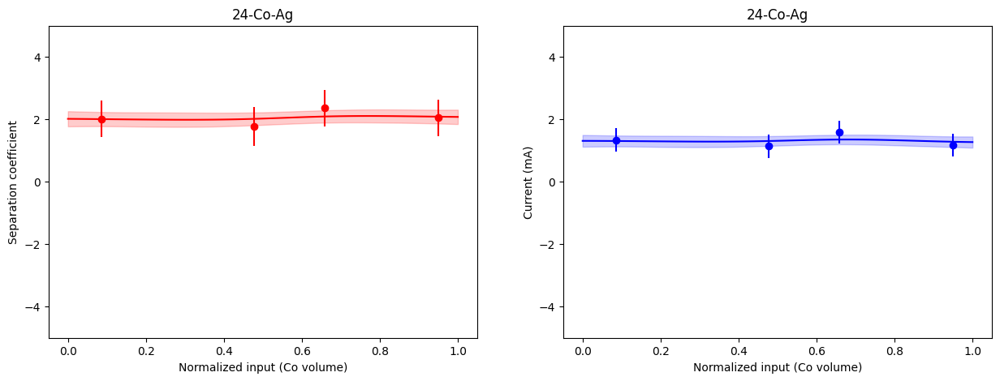

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.8656]), std = tensor([0.0938])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.1314]), std = tensor([0.0008])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


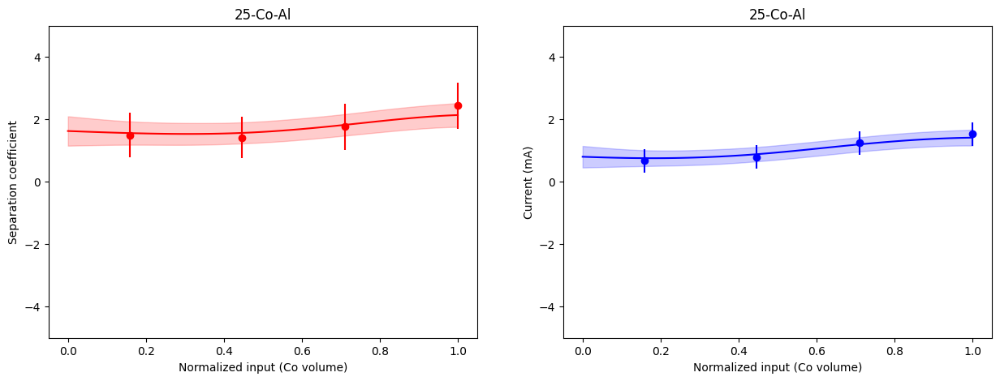

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.5281]), std = tensor([0.0392])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.8892]), std = tensor([0.0001])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


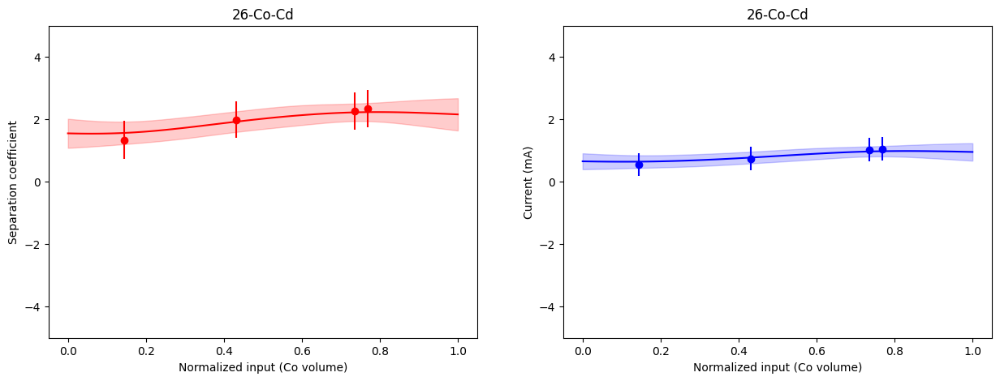

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.1843]), std = tensor([0.0570])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.6987]), std = tensor([0.0067])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


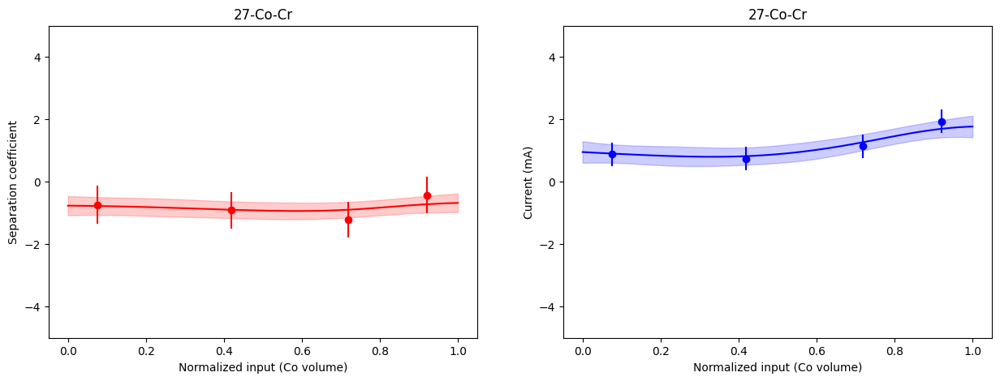

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.3827]), std = tensor([0.0144])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.5501]), std = tensor([0.0004])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


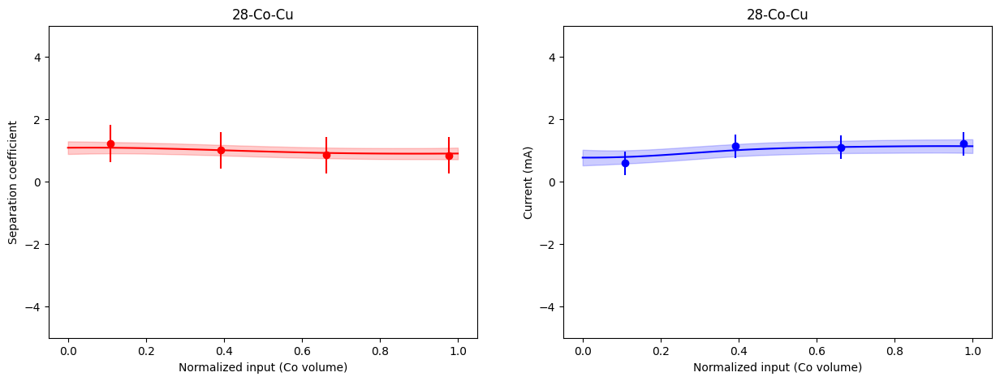

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.7185]), std = tensor([0.1716])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.7053]), std = tensor([7.1008e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


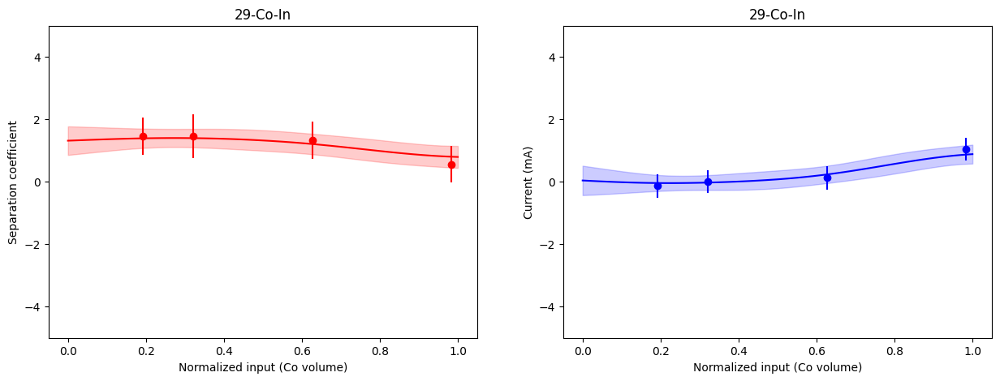

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.8713]), std = tensor([0.0173])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.7043]), std = tensor([0.0013])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


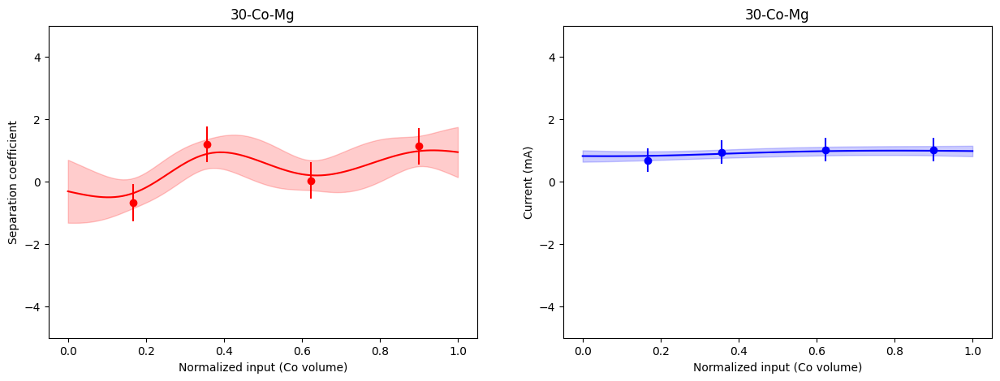

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.1152]), std = tensor([0.0177])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.0426]), std = tensor([0.0025])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


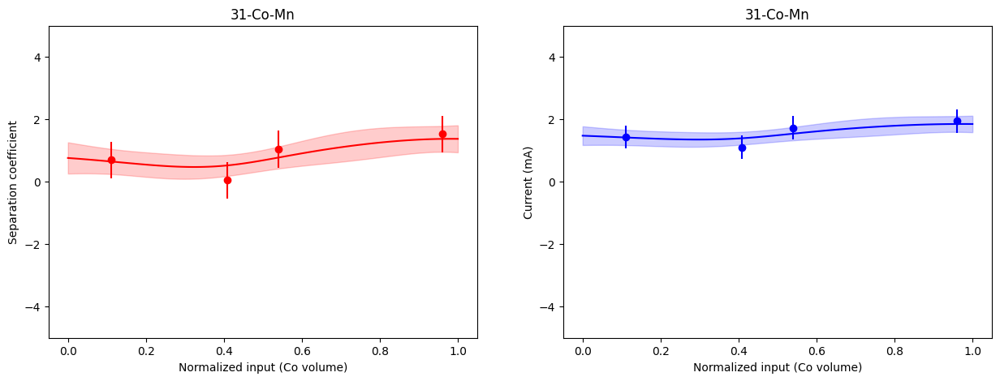

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.3760]), std = tensor([0.0168])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.3672]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


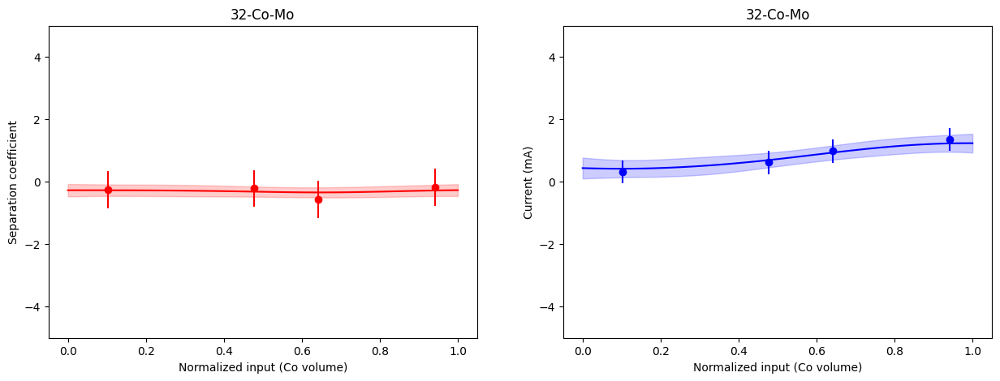

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.2404]), std = tensor([0.1105])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.2773]), std = tensor([0.0009])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


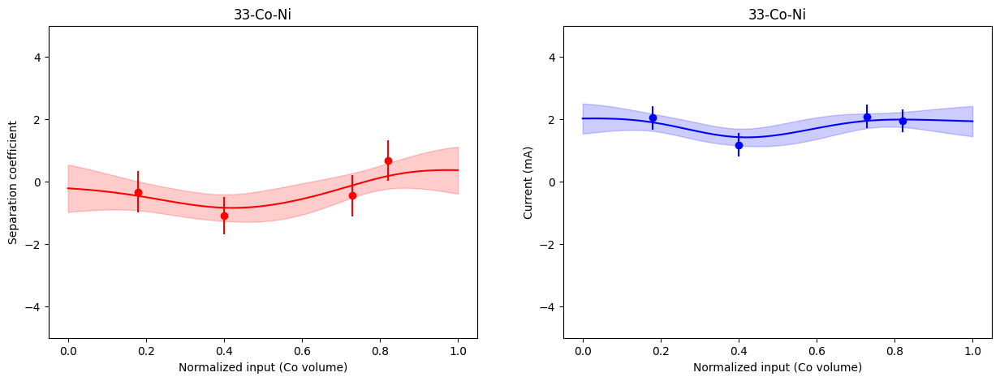

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([5.1416]), std = tensor([0.0084])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.2761]), std = tensor([0.0020])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


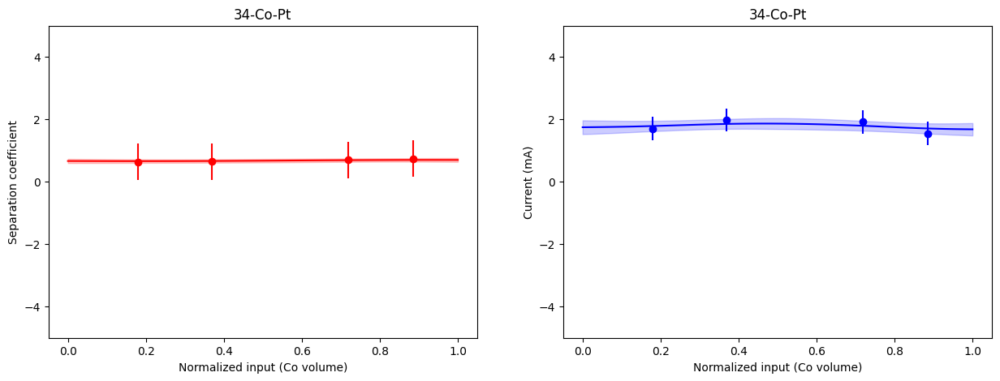

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.8294]), std = tensor([0.0530])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.4738]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


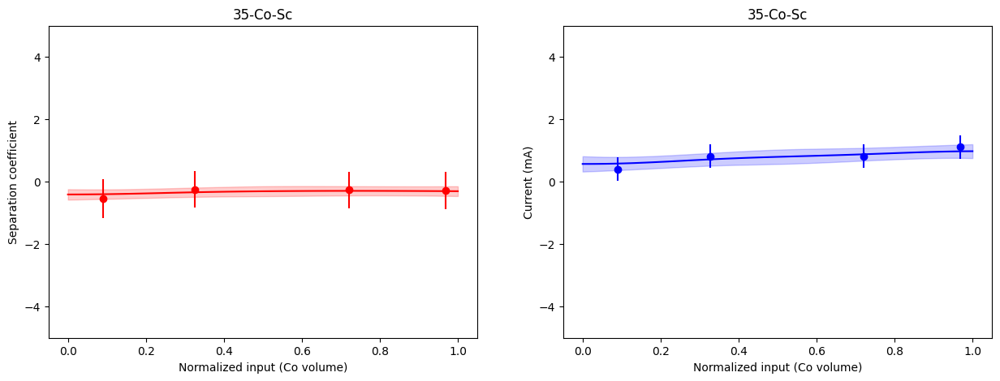

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.1885]), std = tensor([0.0229])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.4273]), std = tensor([0.0012])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


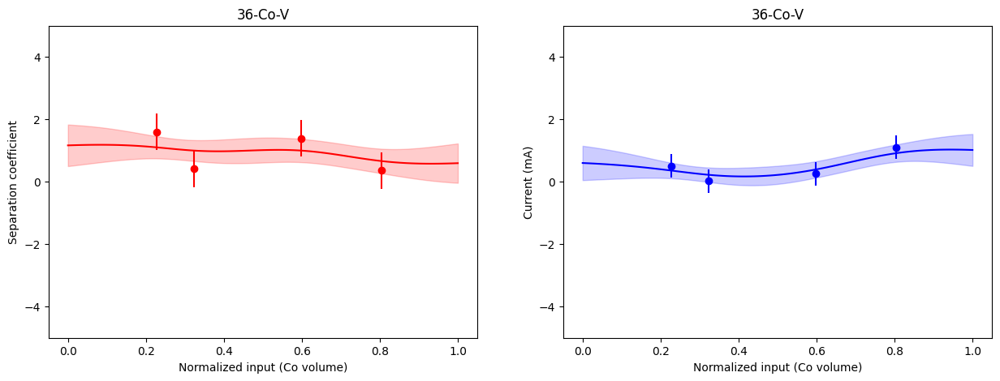

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.0360]), std = tensor([0.1665])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.9896]), std = tensor([0.0004])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


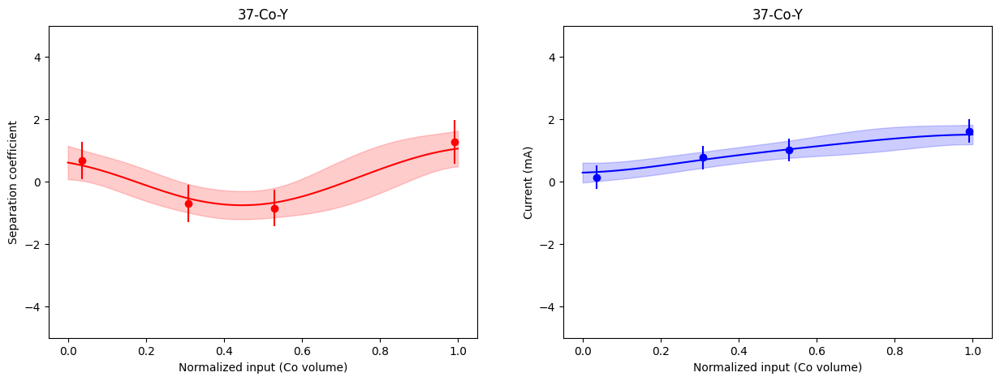

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.7961]), std = tensor([0.0321])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.3623]), std = tensor([0.0006])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


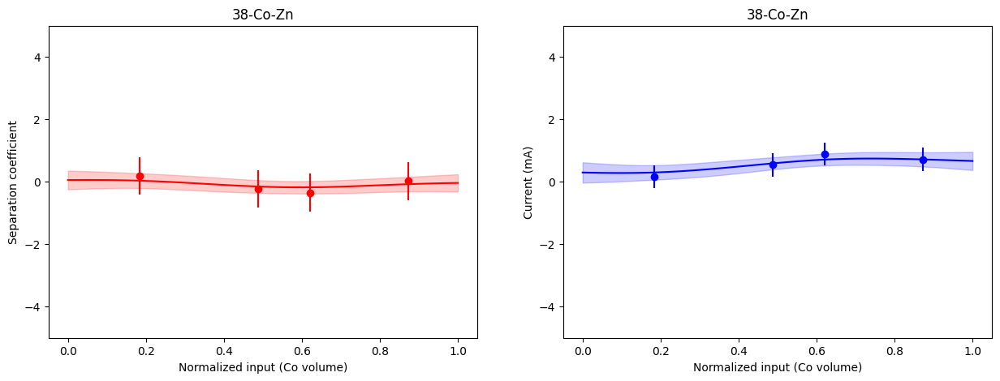

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.4873]), std = tensor([0.0453])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.0063]), std = tensor([0.0001])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


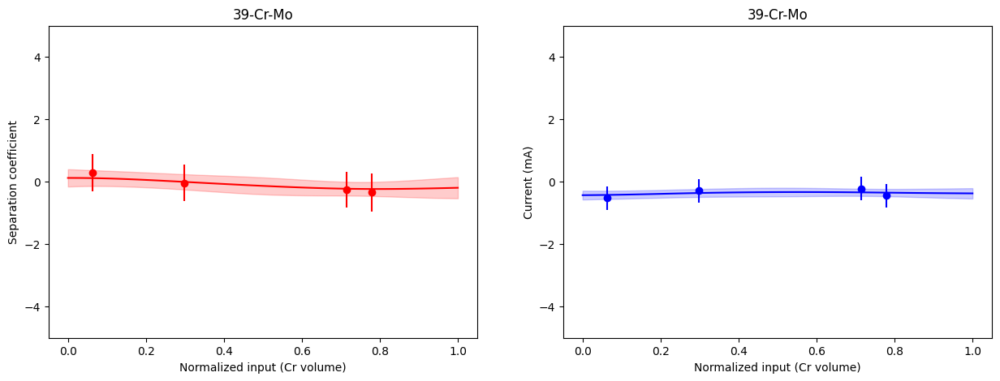

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.1069]), std = tensor([0.2999])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.0456]), std = tensor([1.7932e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


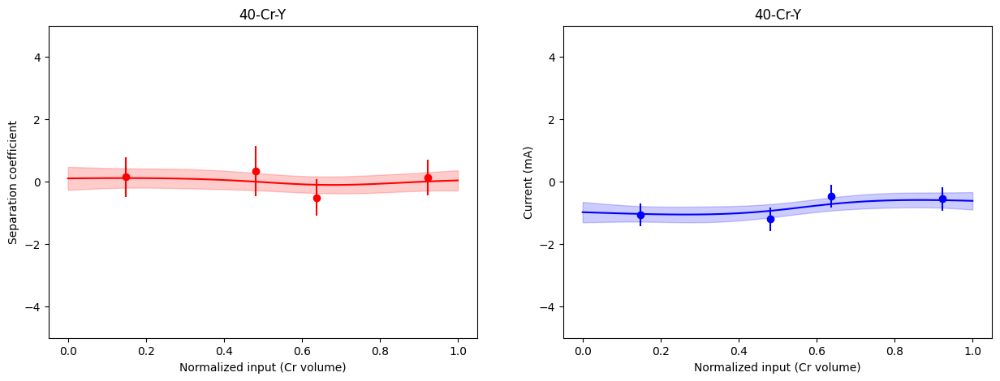

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.4748]), std = tensor([0.0075])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.9373]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


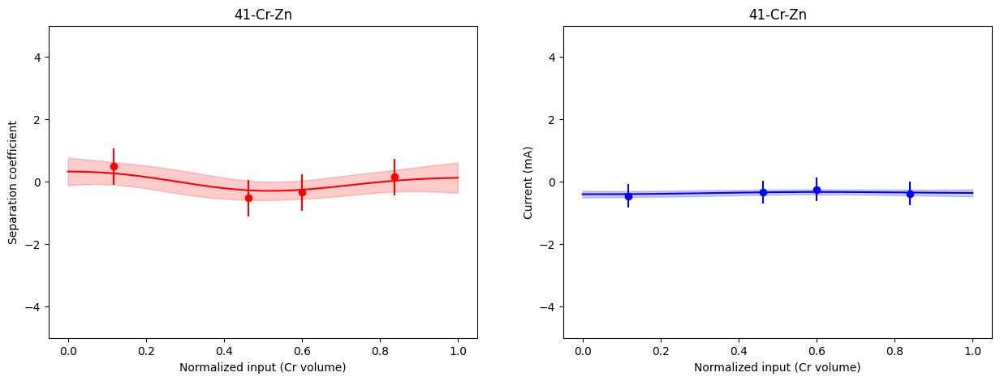

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([3.6087]), std = tensor([0.0080])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.0589]), std = tensor([0.0001])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


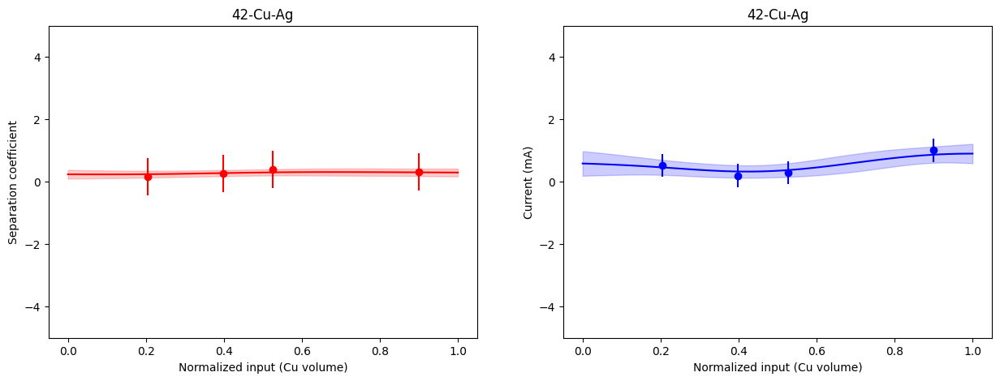

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.3873]), std = tensor([0.0167])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.6803]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


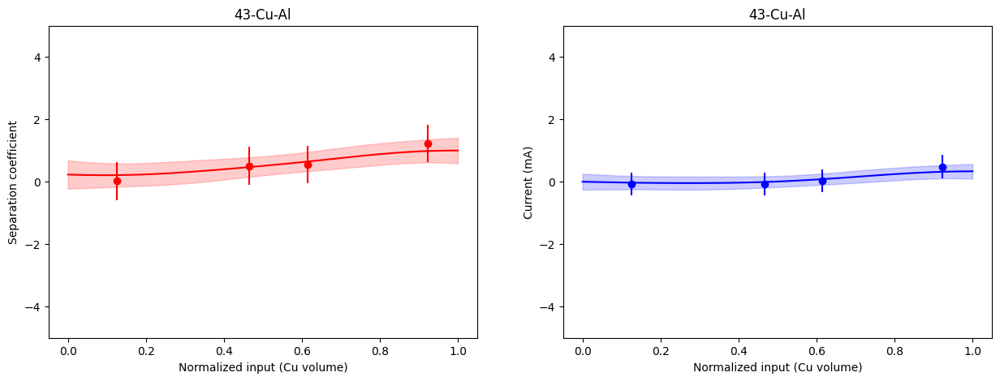

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.4492]), std = tensor([0.0462])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.8005]), std = tensor([0.0003])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


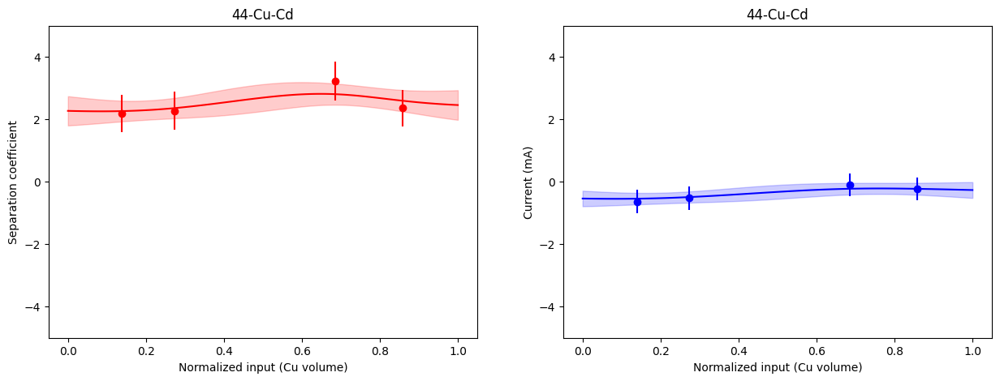

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.0718]), std = tensor([0.0260])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.6067]), std = tensor([0.0015])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


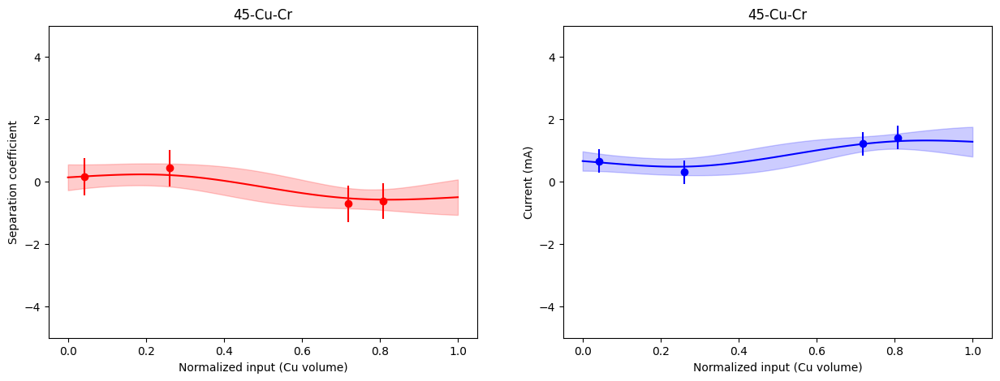

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.0145]), std = tensor([0.0586])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.2410]), std = tensor([0.0001])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


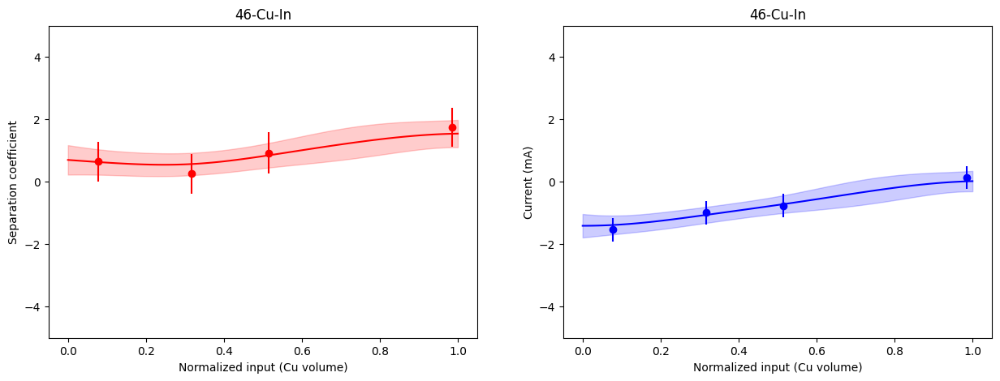

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.5070]), std = tensor([0.0424])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.5888]), std = tensor([0.0007])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


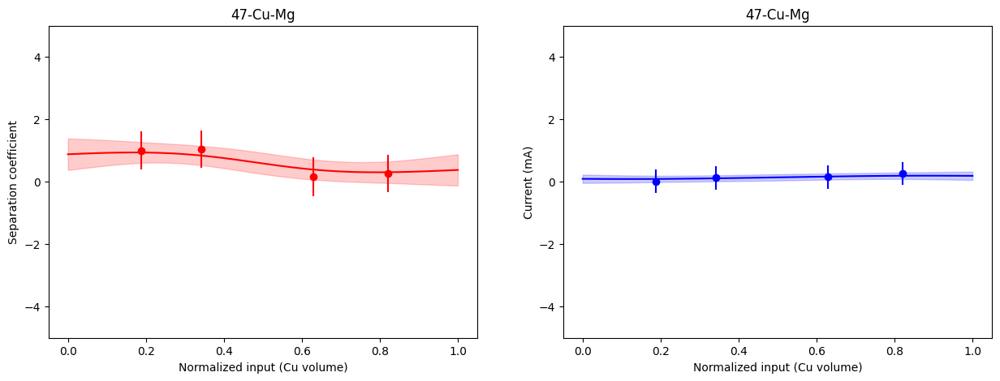

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.0992]), std = tensor([0.0108])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.1599]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


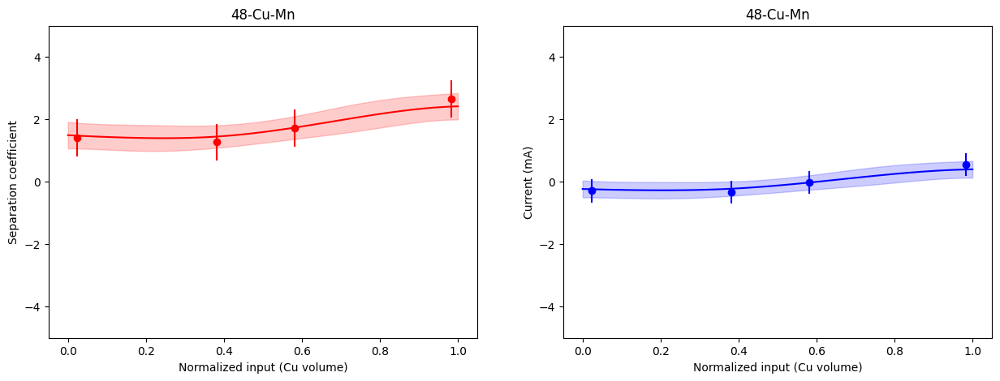

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([3.4815]), std = tensor([0.0136])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.6128]), std = tensor([0.0009])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


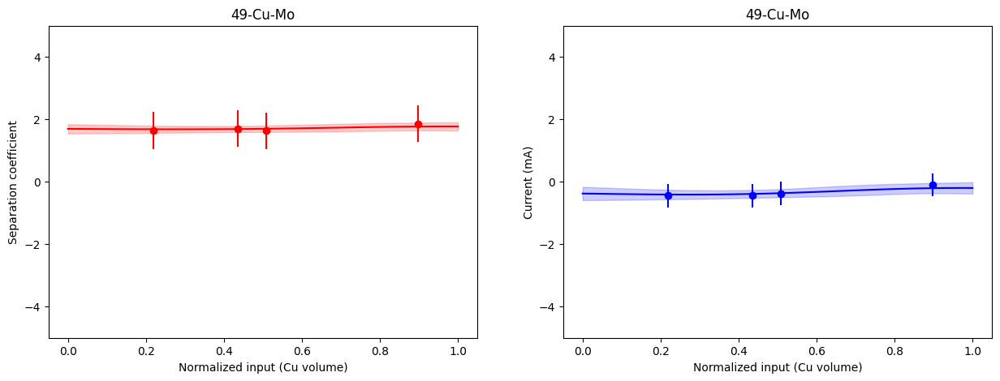

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.5050]), std = tensor([0.0626])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.5166]), std = tensor([0.0006])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


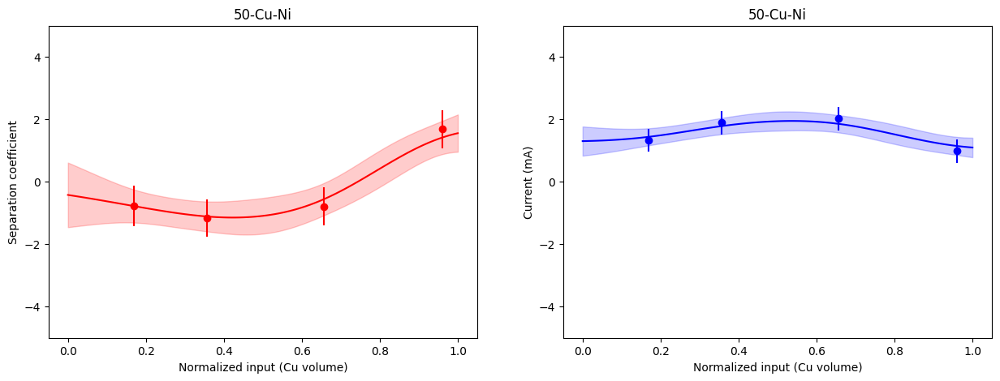

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.2709]), std = tensor([0.0067])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.1985]), std = tensor([0.0013])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


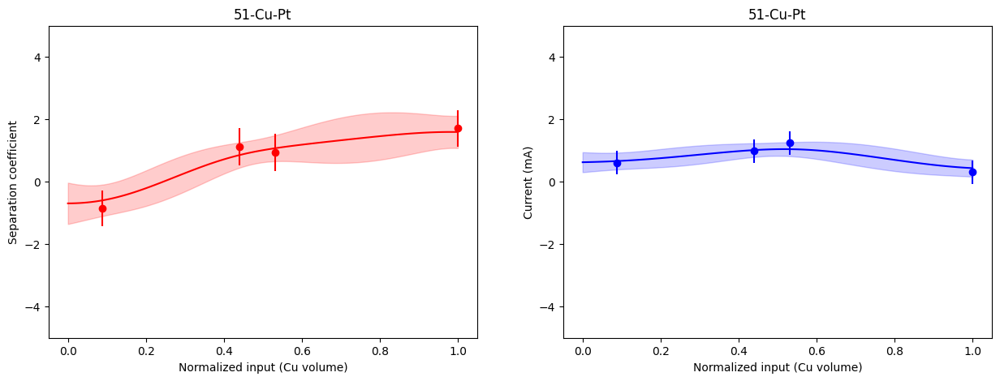

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.1163]), std = tensor([0.0097])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.4380]), std = tensor([0.0007])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


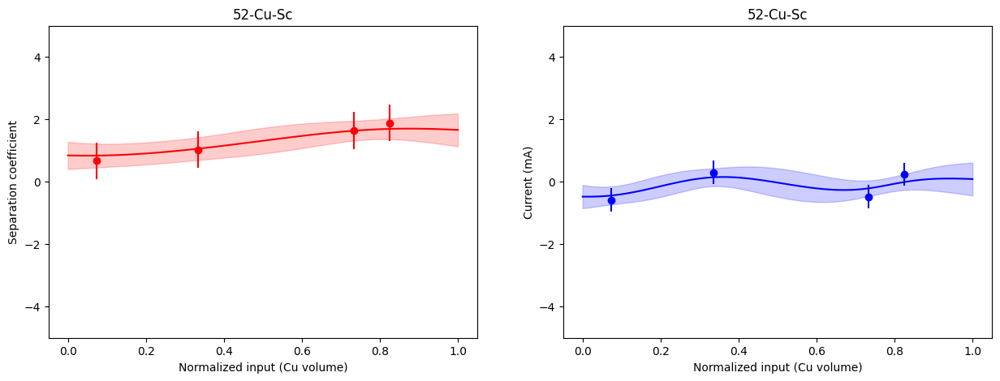

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.2187]), std = tensor([0.0431])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.0900]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


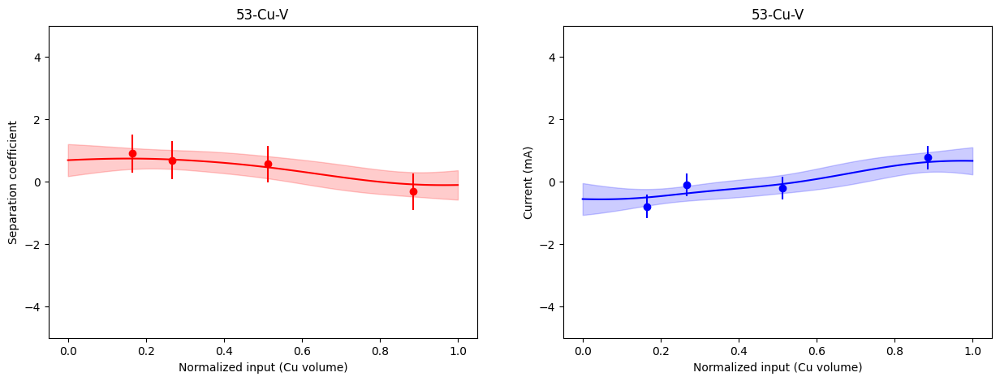

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.1254]), std = tensor([0.0064])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.4457]), std = tensor([0.0004])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


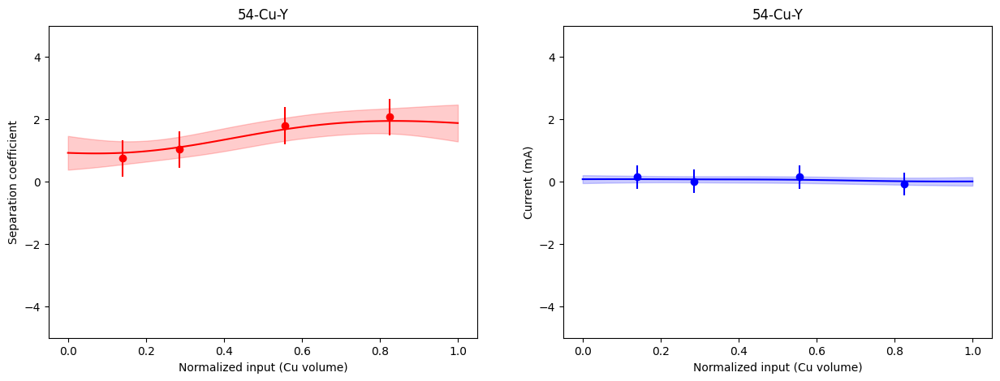

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([5.9997]), std = tensor([0.0196])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.7987]), std = tensor([0.0004])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


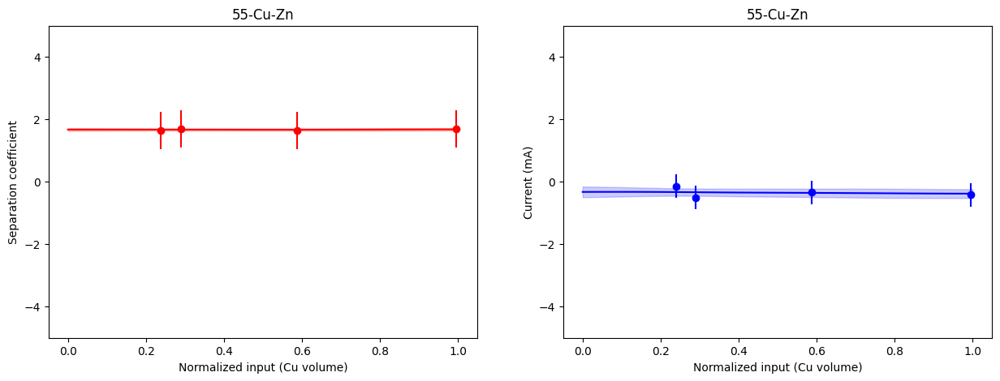

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([3.4311]), std = tensor([0.0573])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.0336]), std = tensor([0.0005])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


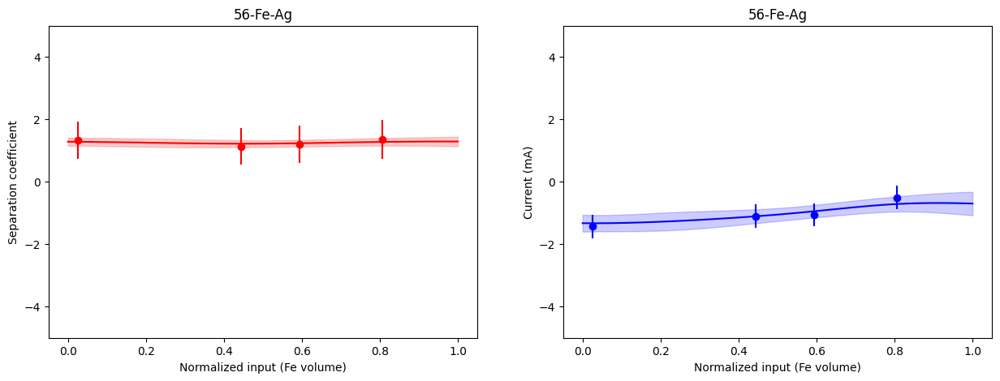

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.2480]), std = tensor([0.0662])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.8996]), std = tensor([0.0006])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


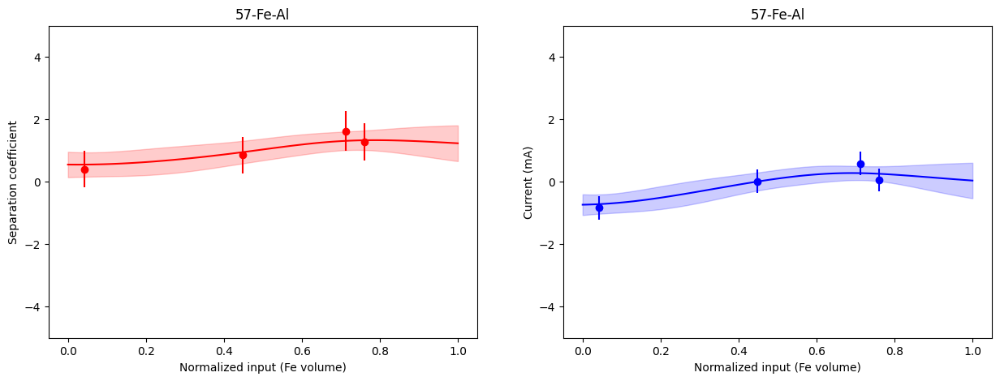

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.4637]), std = tensor([0.0126])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.6761]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


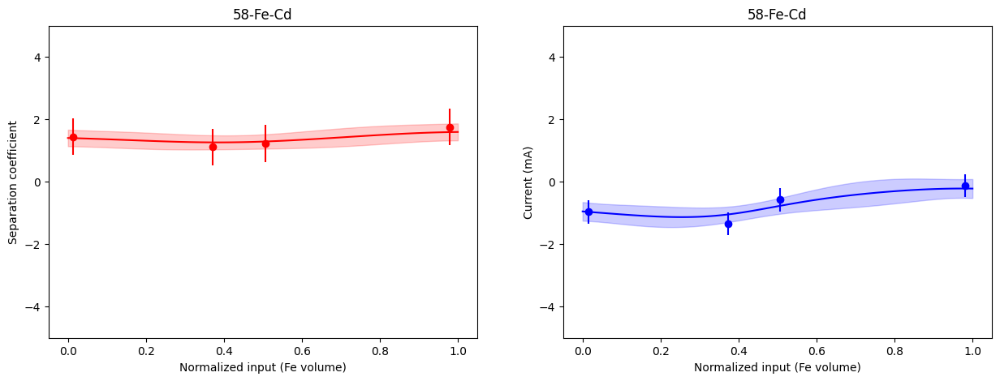

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.2717]), std = tensor([0.0176])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.7491]), std = tensor([0.0003])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


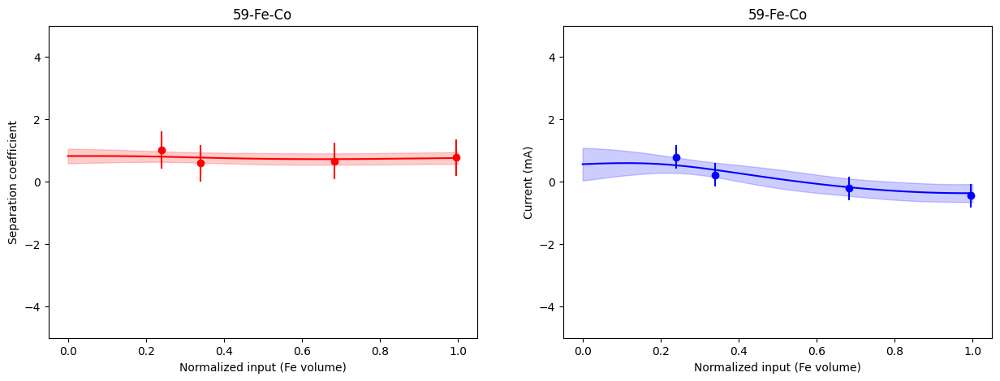

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.5981]), std = tensor([0.0382])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.3397]), std = tensor([0.0007])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


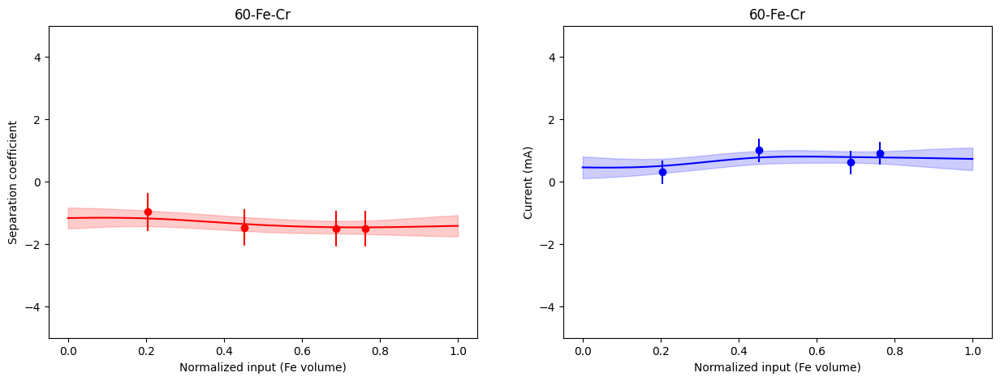

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.4765]), std = tensor([0.0163])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.2827]), std = tensor([0.0005])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


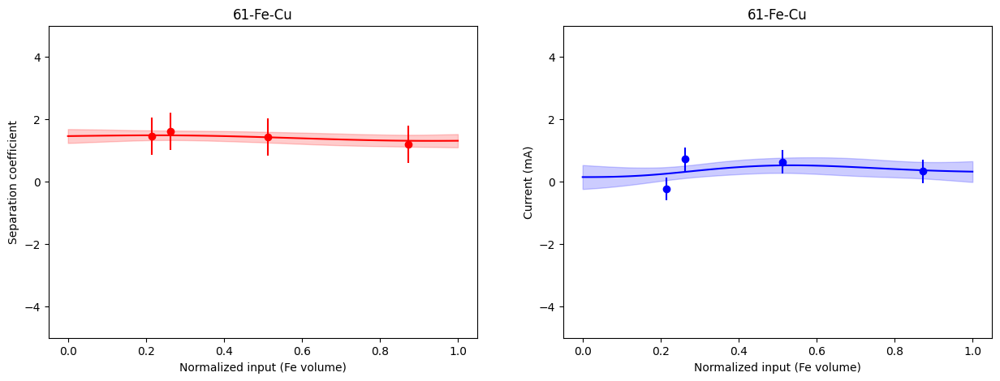

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([3.0241]), std = tensor([0.0212])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.3417]), std = tensor([9.4649e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


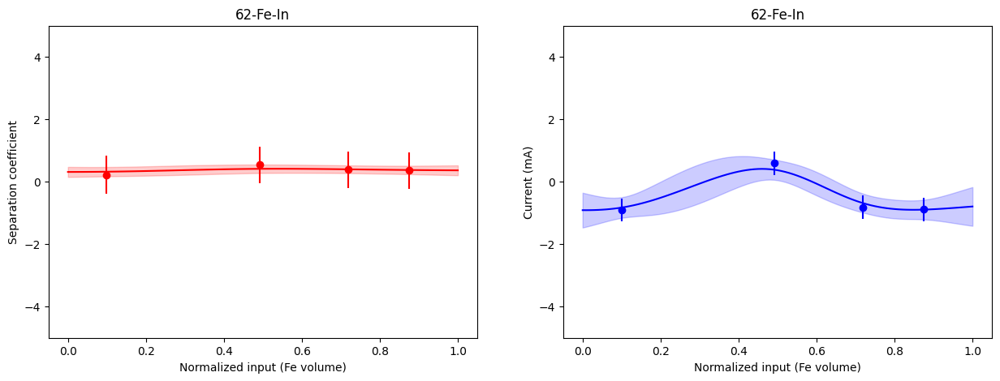

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.7415]), std = tensor([0.0143])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.4884]), std = tensor([0.0004])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


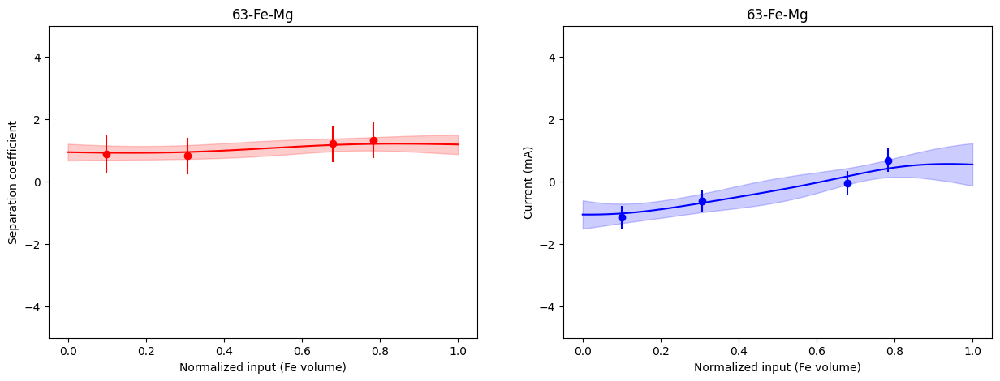

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.7931]), std = tensor([0.0414])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.2537]), std = tensor([9.8244e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


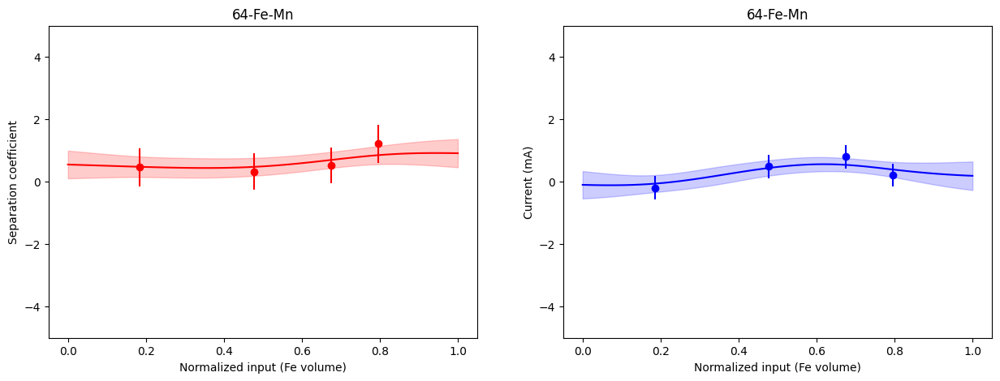

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([4.2119]), std = tensor([0.4066])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-2.0735]), std = tensor([0.0007])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


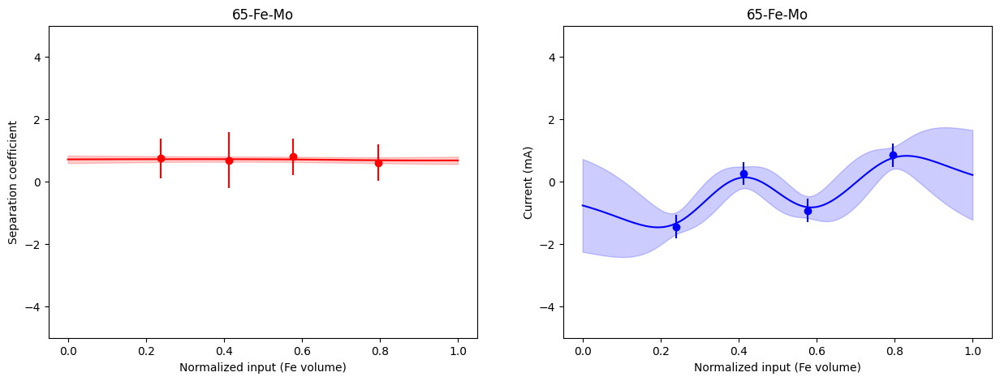

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.0082]), std = tensor([0.0311])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.8017]), std = tensor([0.0003])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


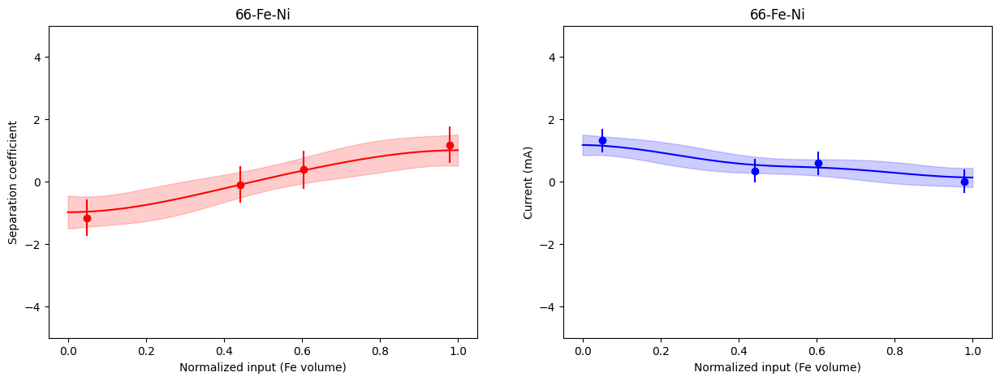

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.4084]), std = tensor([0.0022])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.3196]), std = tensor([0.0019])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


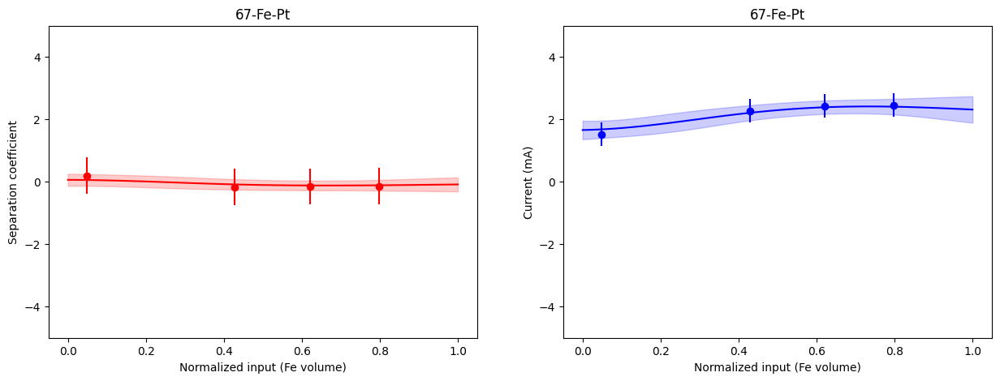

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.2158]), std = tensor([0.0356])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.7502]), std = tensor([0.0004])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


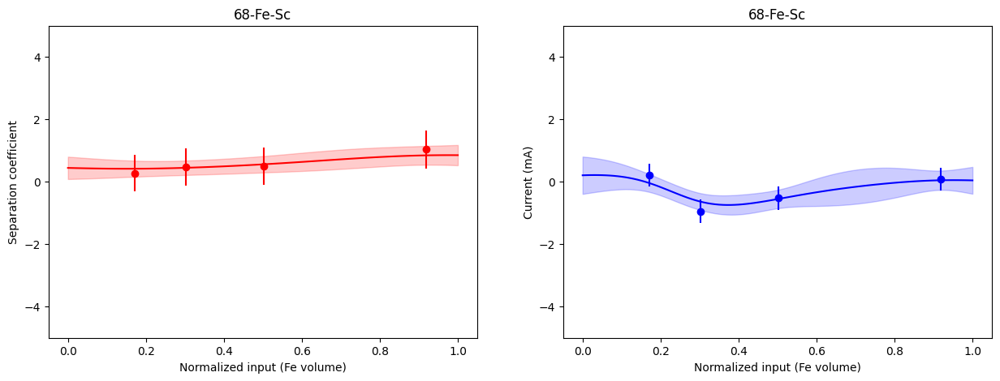

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.5869]), std = tensor([0.0591])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.4837]), std = tensor([0.0004])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


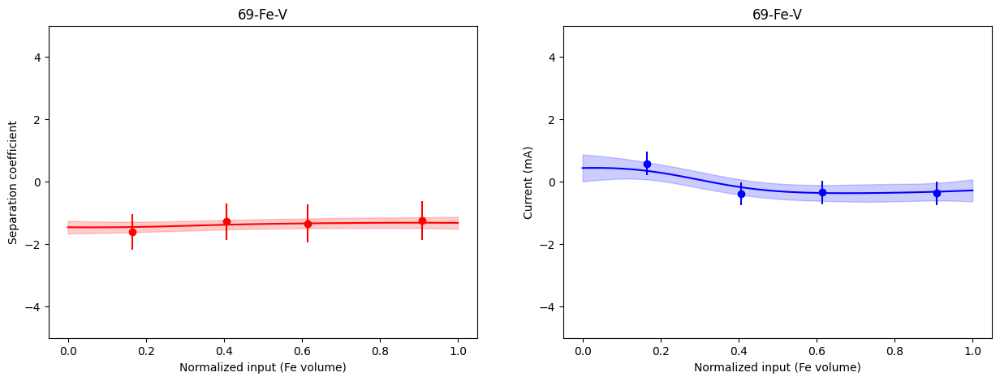

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.2742]), std = tensor([0.0037])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.7997]), std = tensor([0.0003])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


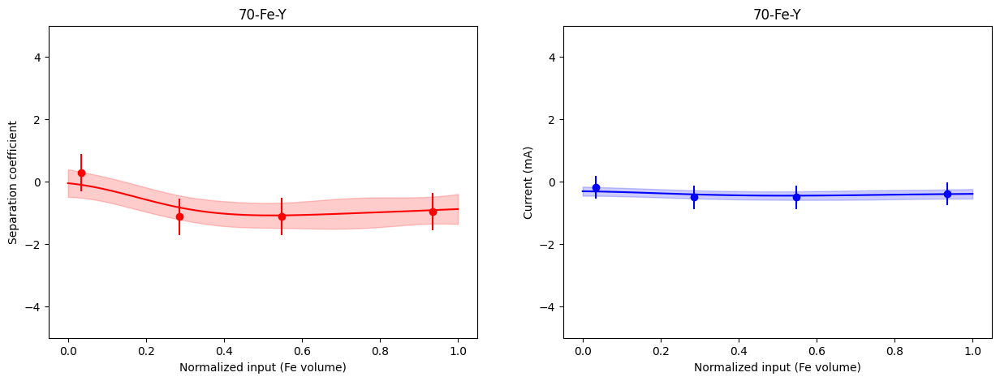

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.5009]), std = tensor([0.0714])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.1622]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


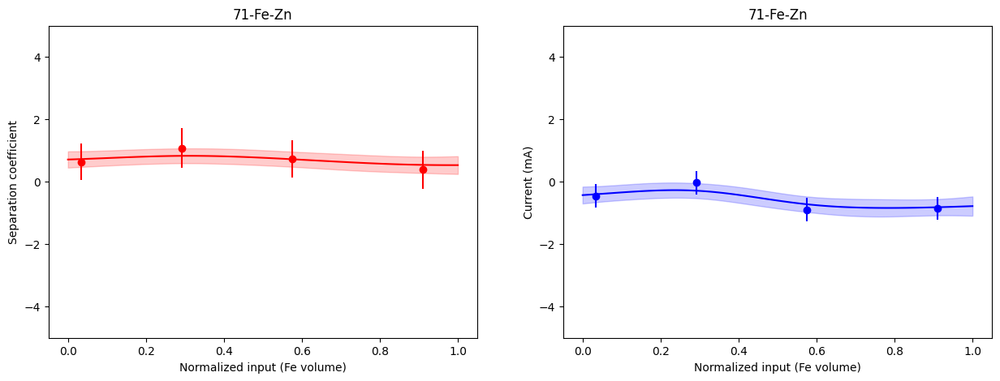

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.7400]), std = tensor([0.0184])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.5206]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


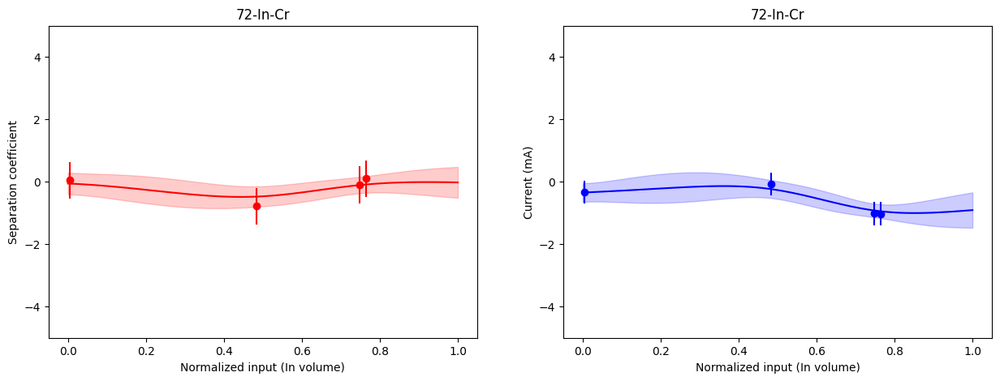

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.0126]), std = tensor([0.1524])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.6253]), std = tensor([0.0003])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


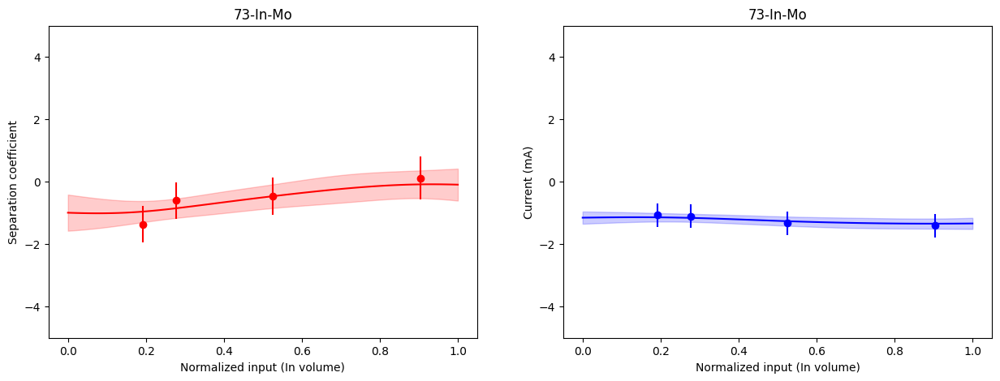

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.8947]), std = tensor([0.1239])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.7563]), std = tensor([9.8365e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


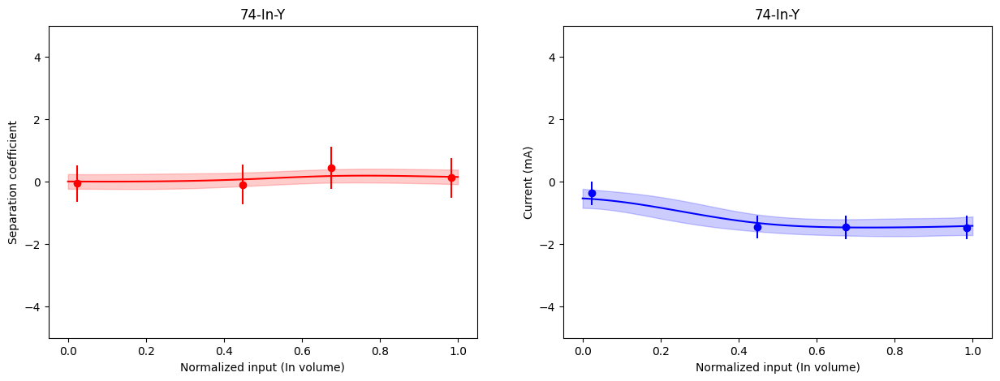

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.3602]), std = tensor([0.0513])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.6989]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


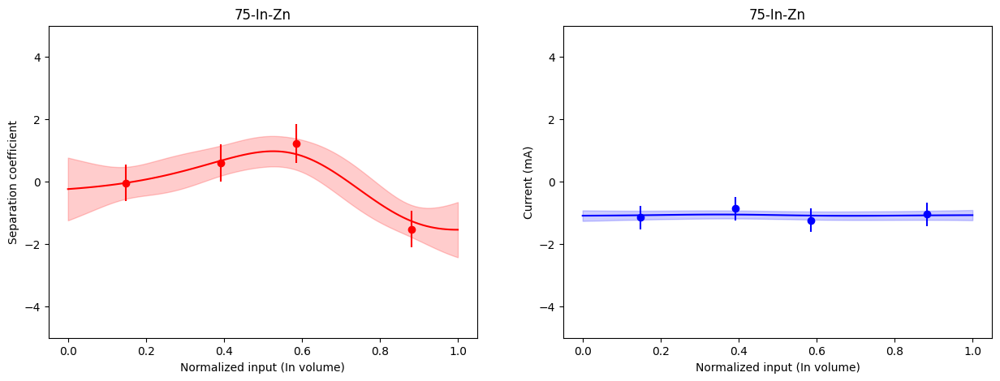

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.0061]), std = tensor([0.0737])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([4.4540]), std = tensor([6.8999e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


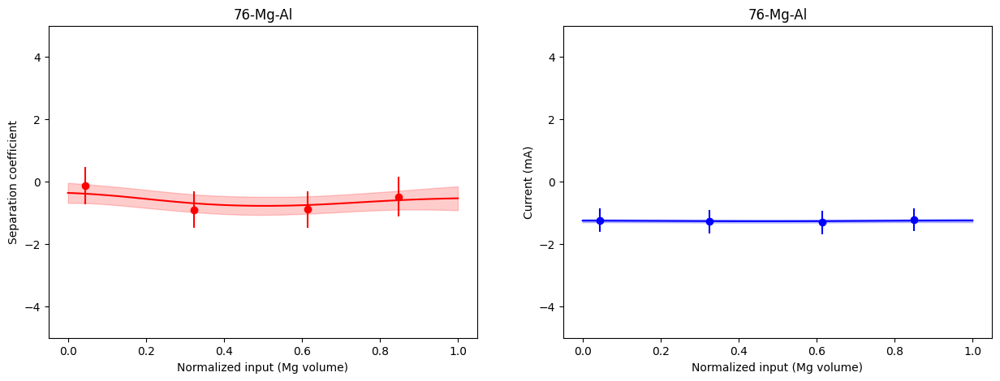

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.1763]), std = tensor([0.0083])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.5971]), std = tensor([0.0005])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


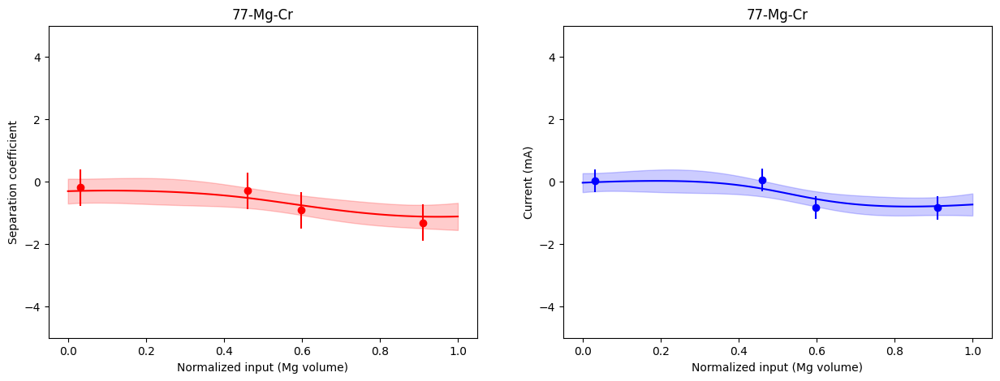

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.3179]), std = tensor([0.2038])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.5164]), std = tensor([0.0004])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


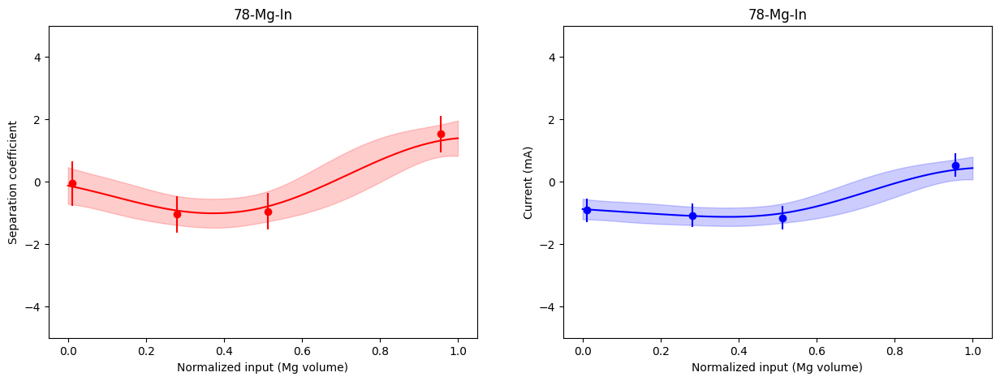

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.7221]), std = tensor([0.1064])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.1859]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


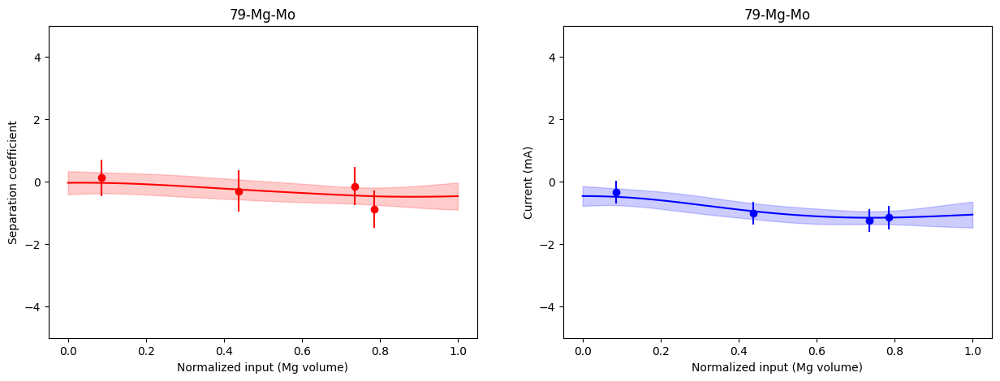

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.6170]), std = tensor([0.0072])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.9686]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


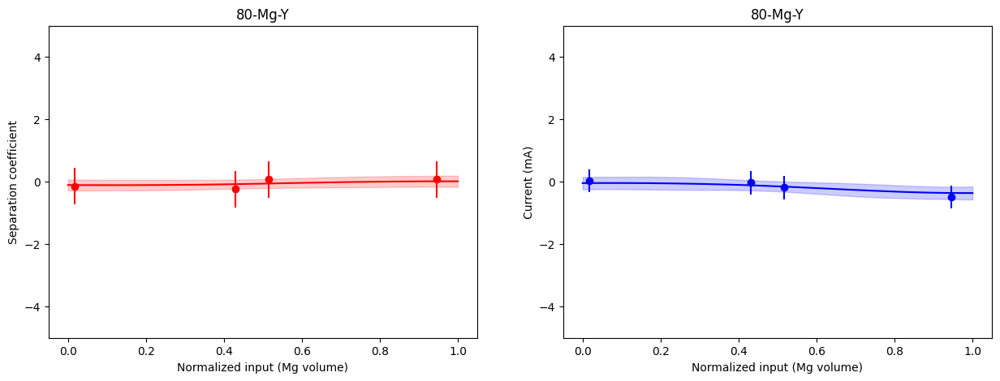

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.7043]), std = tensor([0.0397])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.2019]), std = tensor([3.9952e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


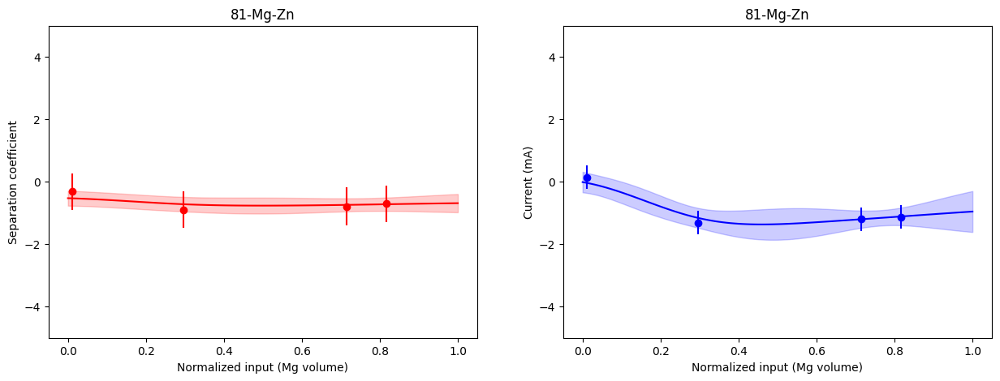

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.9626]), std = tensor([0.0059])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([7.0222]), std = tensor([0.0142])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


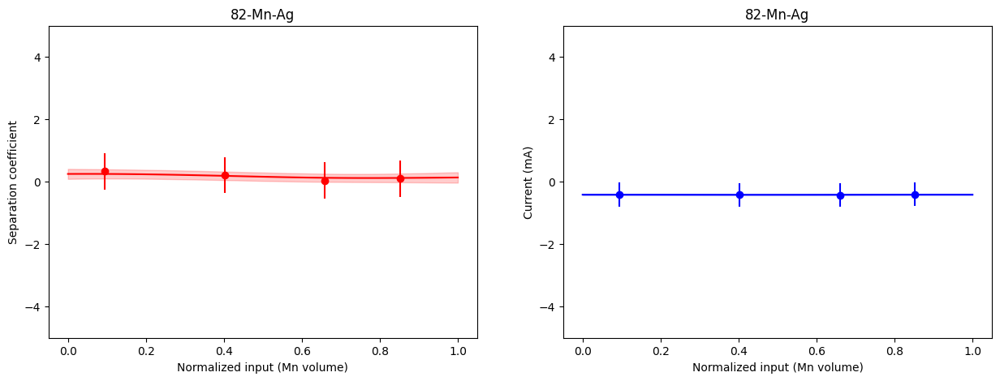

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.1471]), std = tensor([0.0319])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([3.0716]), std = tensor([0.0009])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


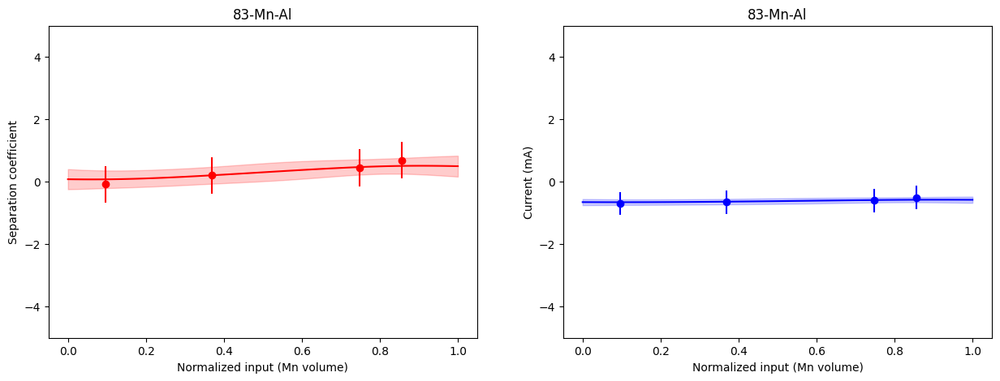

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.3248]), std = tensor([0.2339])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([3.2842]), std = tensor([0.0001])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


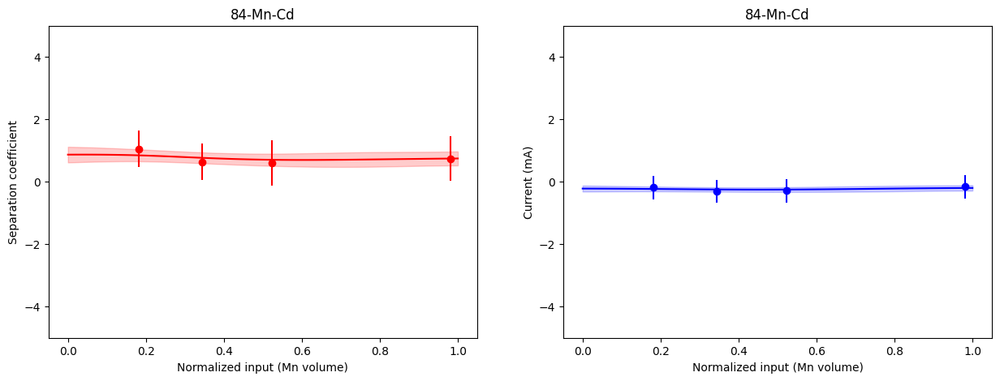

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([4.3826]), std = tensor([0.0152])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.9278]), std = tensor([0.0001])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


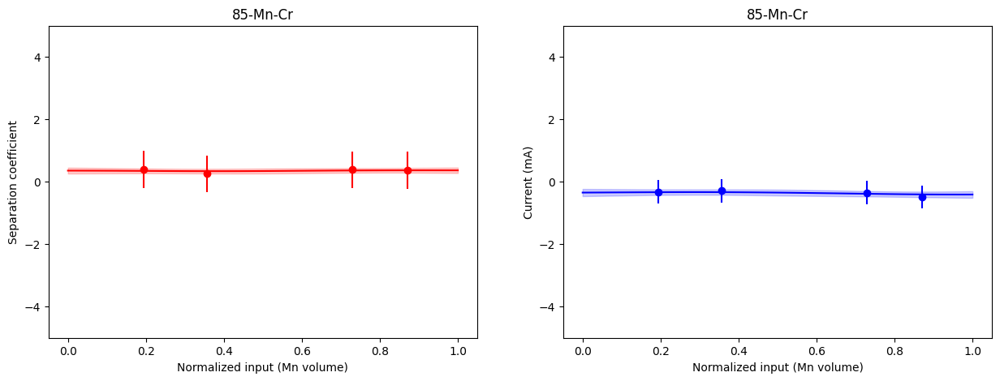

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([5.3605]), std = tensor([0.0204])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.9365]), std = tensor([0.0004])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


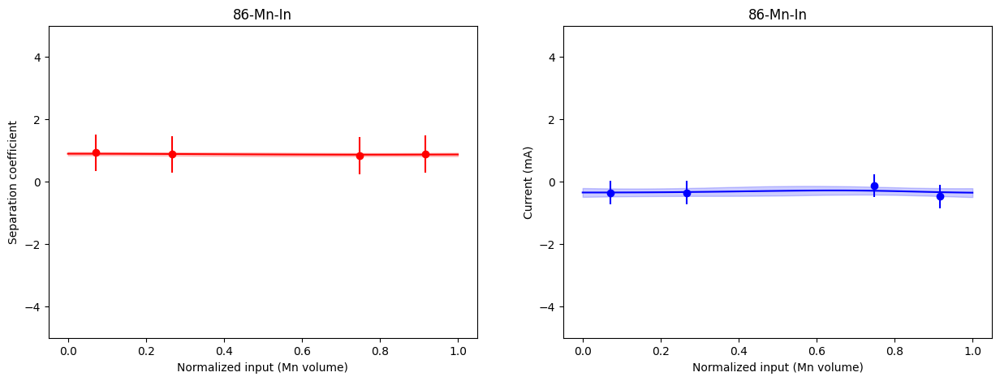

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.4004]), std = tensor([0.0144])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.4613]), std = tensor([0.0001])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


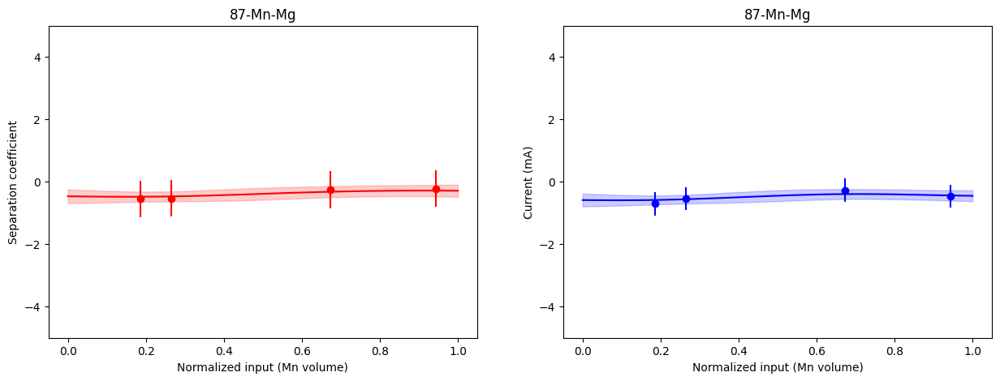

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.2560]), std = tensor([0.3857])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.5664]), std = tensor([0.0032])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


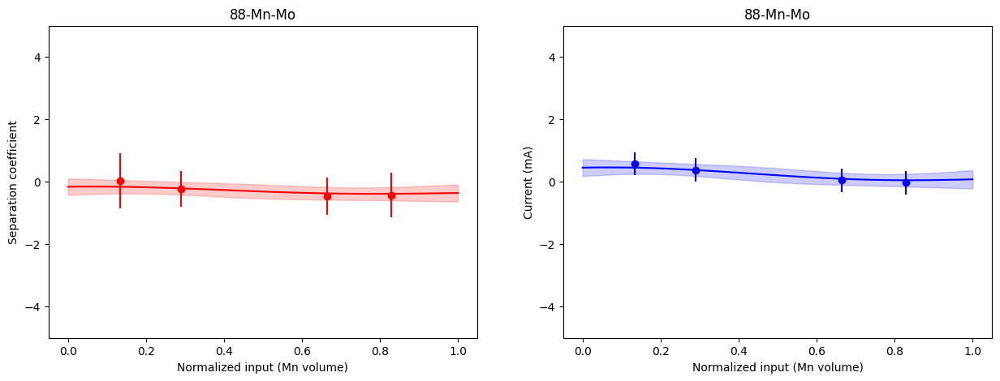

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.3518]), std = tensor([0.0272])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.3643]), std = tensor([0.0029])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


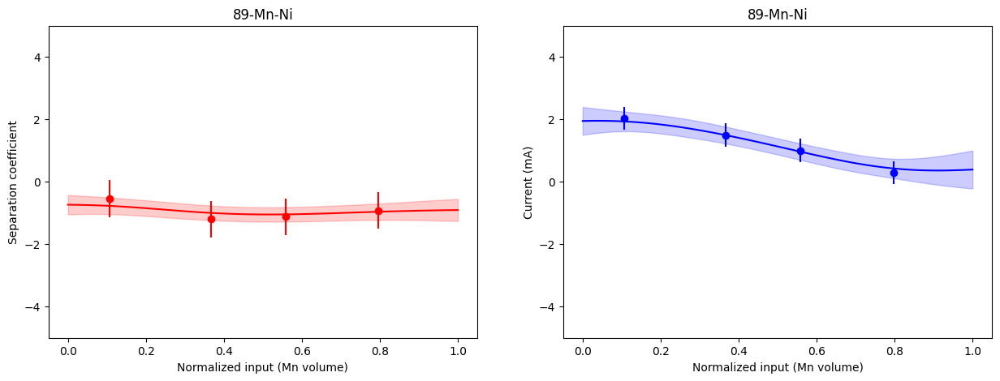

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([3.1814]), std = tensor([0.0246])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.7487]), std = tensor([0.0013])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


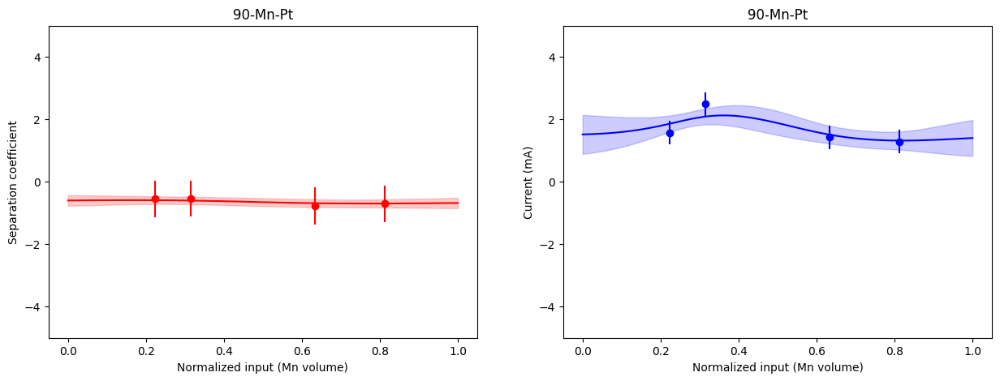

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.5183]), std = tensor([0.0558])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.5552]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


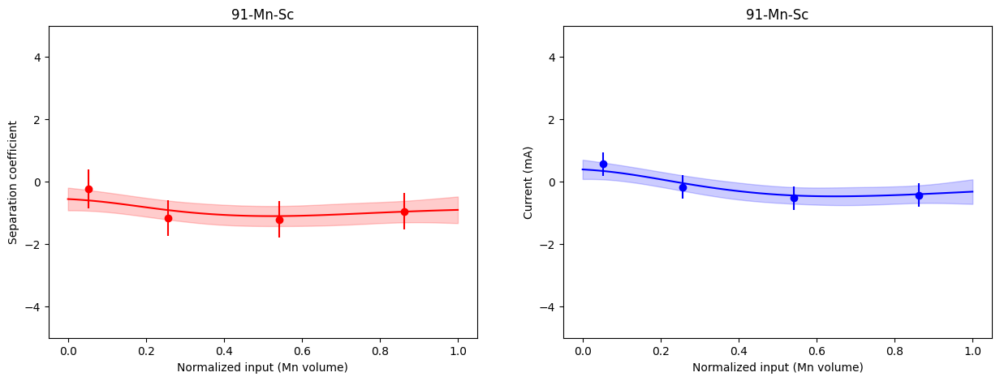

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.3454]), std = tensor([0.0322])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.8841]), std = tensor([0.0029])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


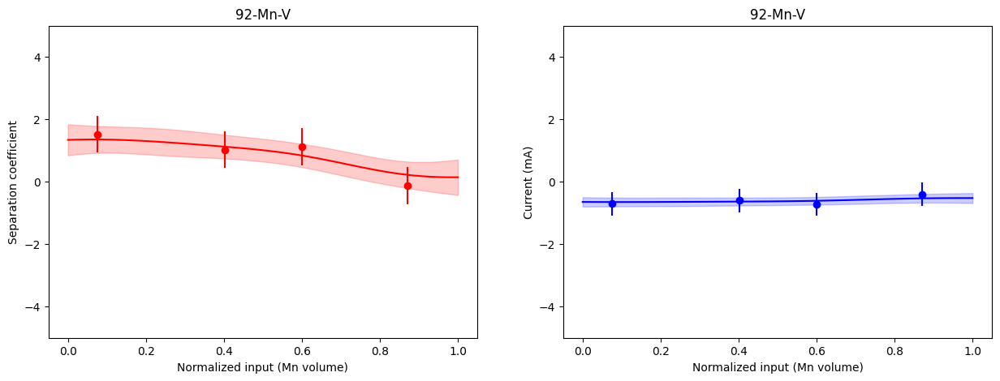

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.9220]), std = tensor([0.1811])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([4.7670]), std = tensor([8.3067e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


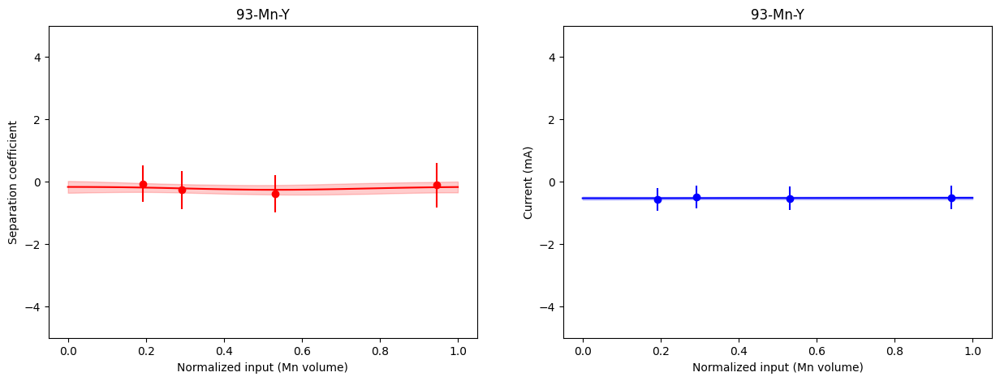

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.2093]), std = tensor([0.0236])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.7692]), std = tensor([0.0013])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


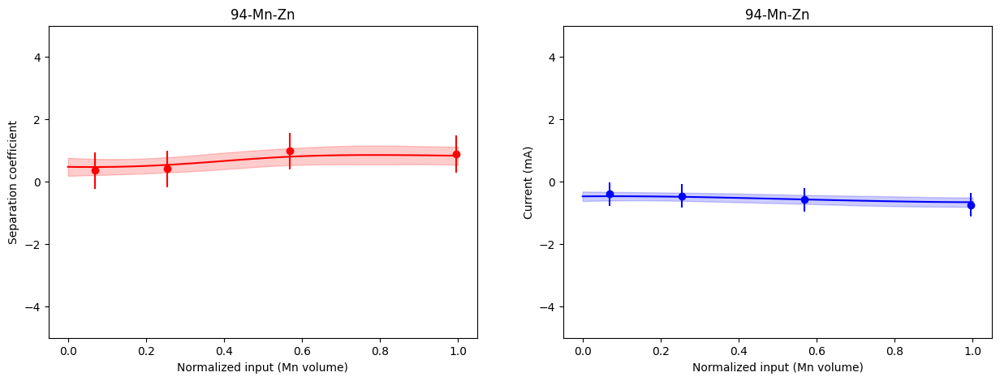

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([3.6539]), std = tensor([0.0023])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.7209]), std = tensor([0.0014])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


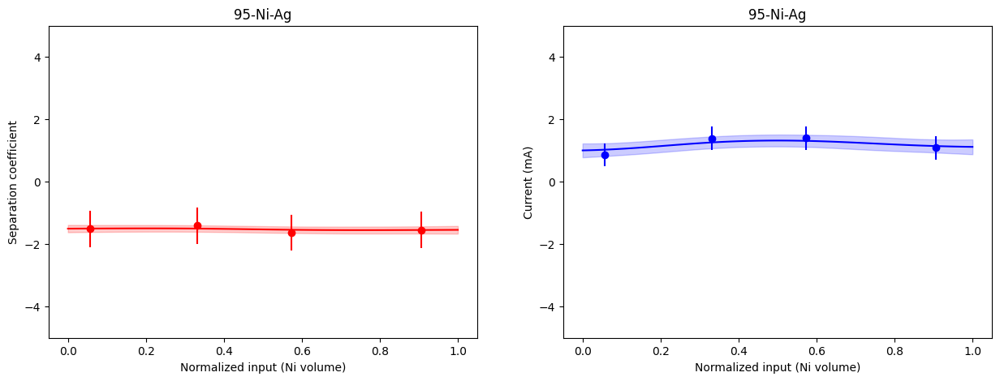

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.4973]), std = tensor([0.0400])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.2396]), std = tensor([3.4039e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


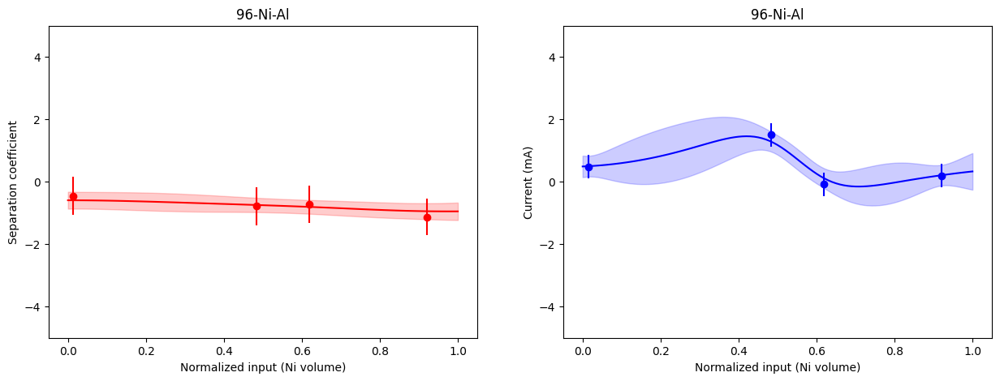

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.8396]), std = tensor([0.0764])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.2224]), std = tensor([0.0009])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


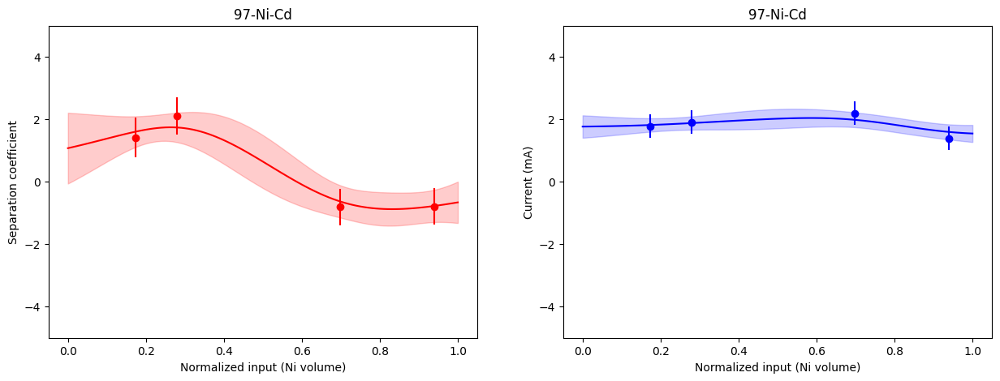

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.7341]), std = tensor([0.0114])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-2.6982]), std = tensor([0.0003])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


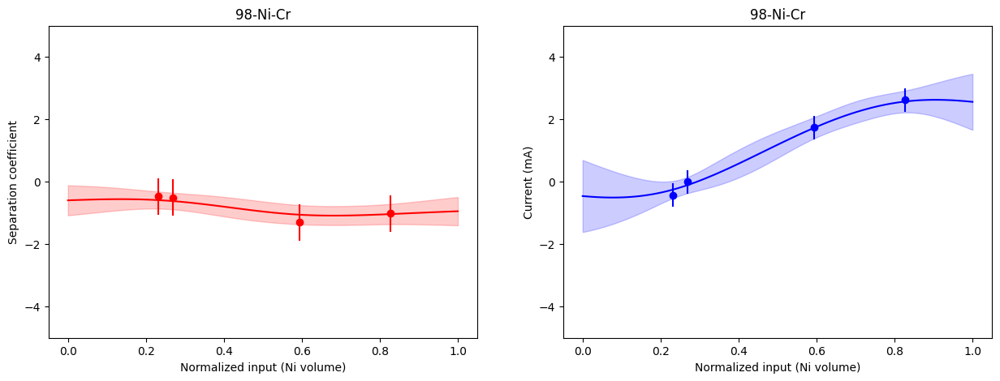

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.3342]), std = tensor([0.0846])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.5261]), std = tensor([0.0003])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


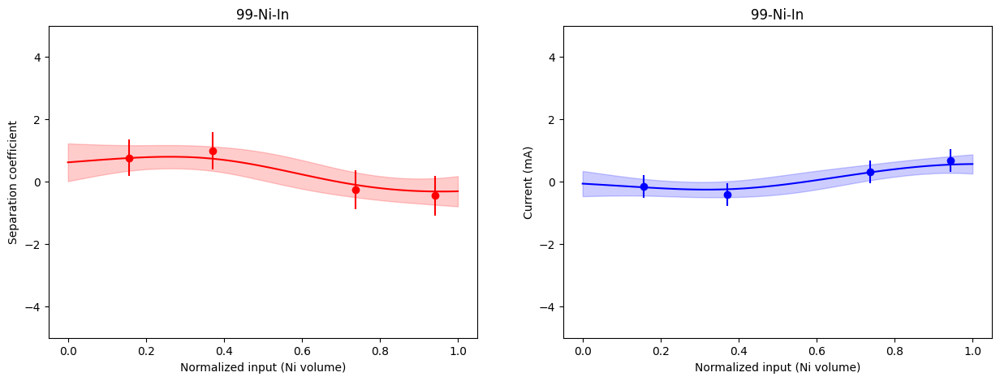

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.3459]), std = tensor([0.0305])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-2.1511]), std = tensor([0.0005])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


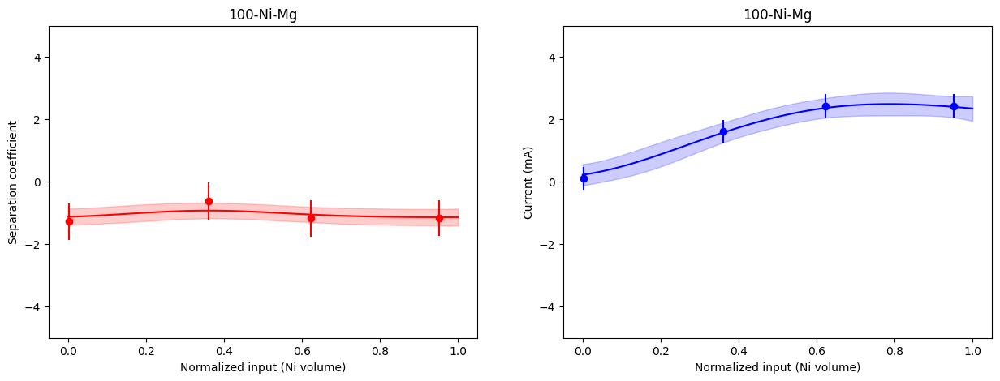

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([3.3774]), std = tensor([0.0018])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.7864]), std = tensor([0.0003])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


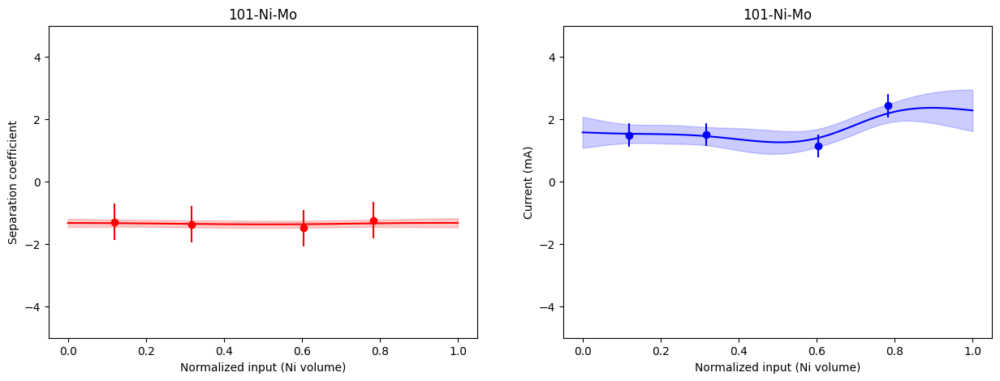

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.2888]), std = tensor([0.0440])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.6481]), std = tensor([0.0009])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


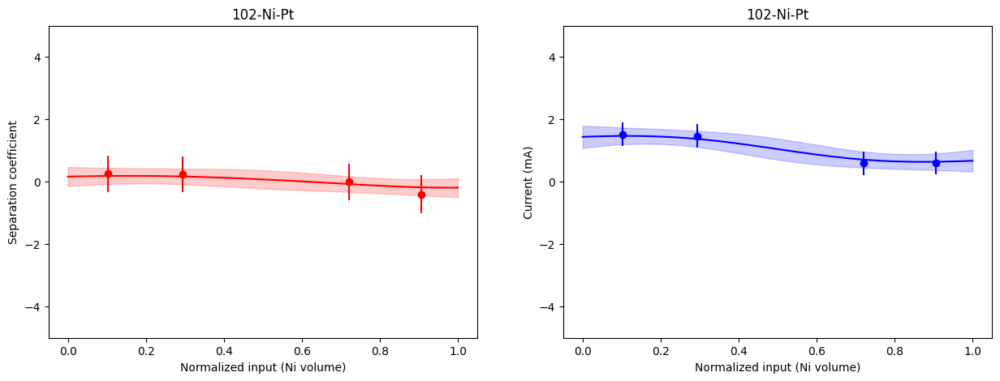

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.3312]), std = tensor([0.2411])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.1044]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


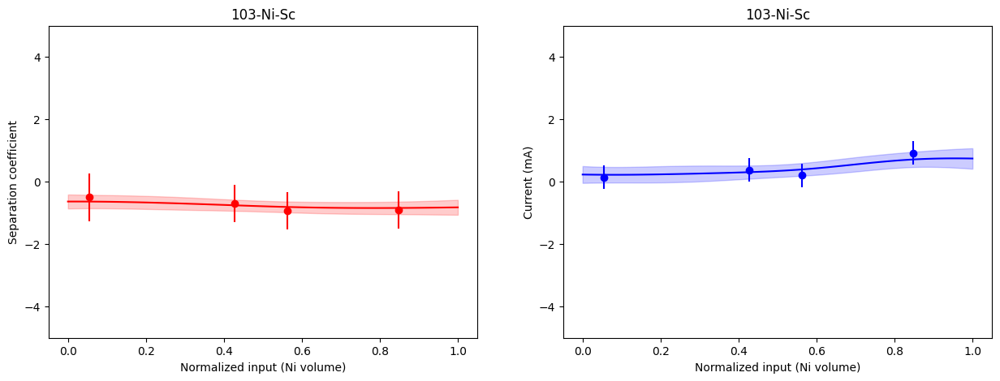

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.7751]), std = tensor([0.0009])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-2.1421]), std = tensor([0.0005])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


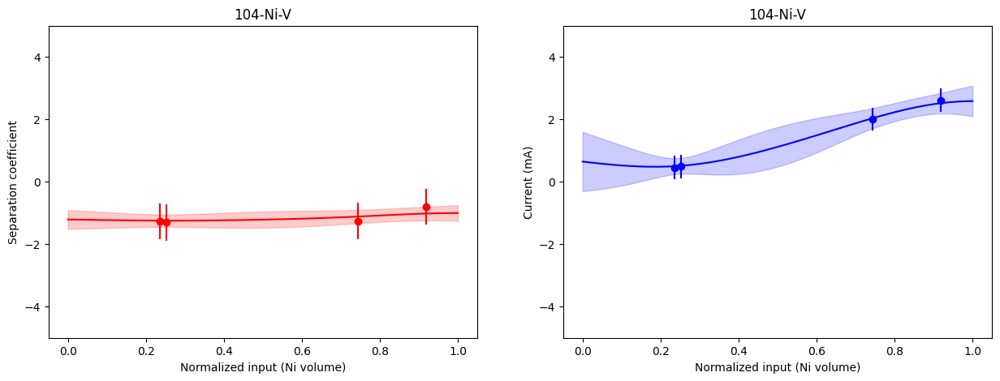

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.6666]), std = tensor([0.0088])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.2186]), std = tensor([0.0007])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


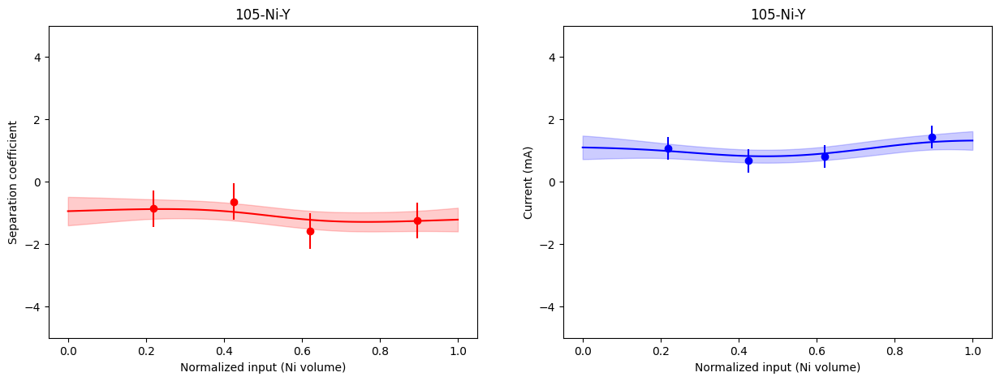

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.4474]), std = tensor([0.0131])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.1114]), std = tensor([0.0003])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


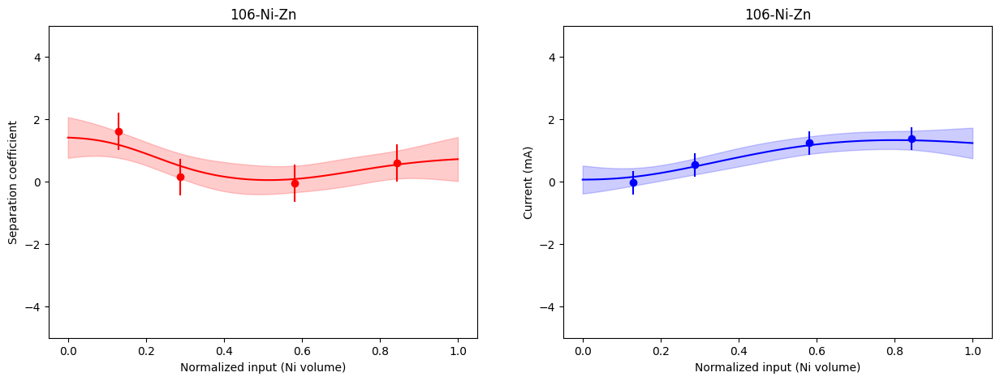

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.6071]), std = tensor([0.0674])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.7780]), std = tensor([0.0014])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


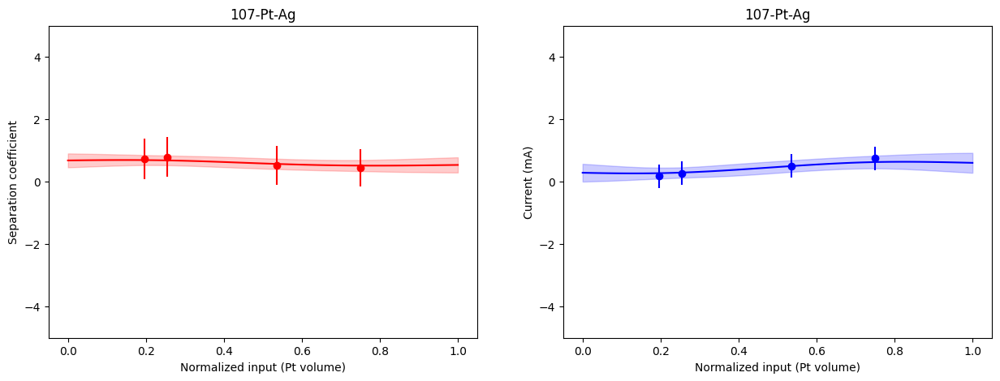

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.1720]), std = tensor([0.0045])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.3790]), std = tensor([0.0001])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


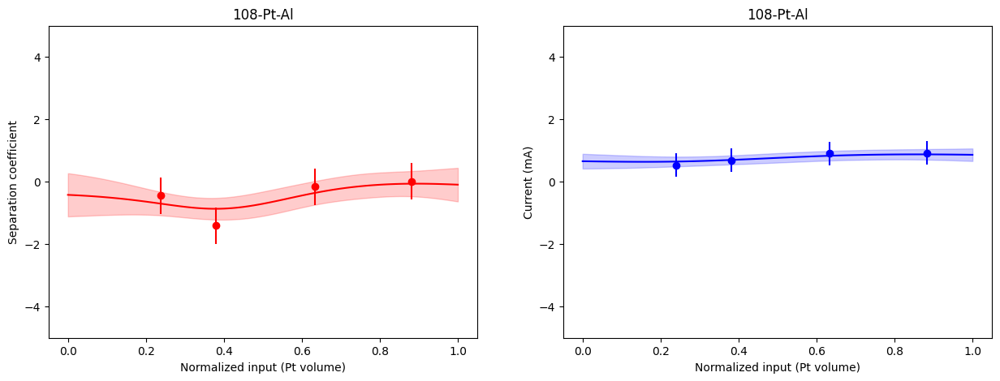

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.8029]), std = tensor([0.0007])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.4806]), std = tensor([0.0027])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


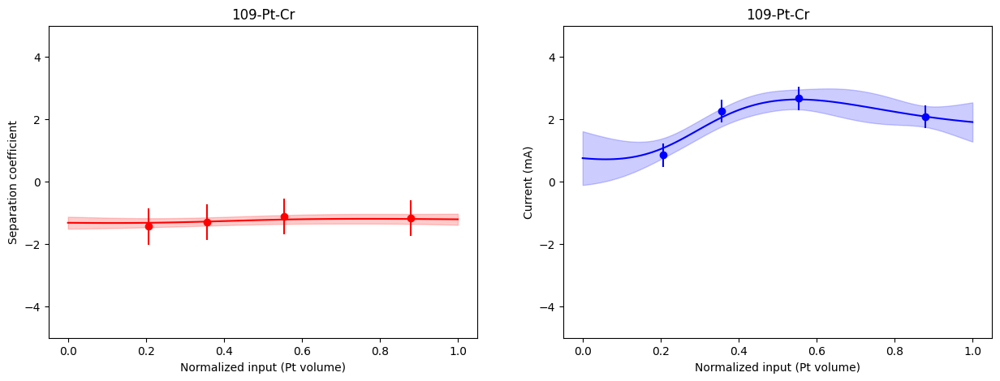

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([4.2014]), std = tensor([0.0357])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.8120]), std = tensor([0.0026])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


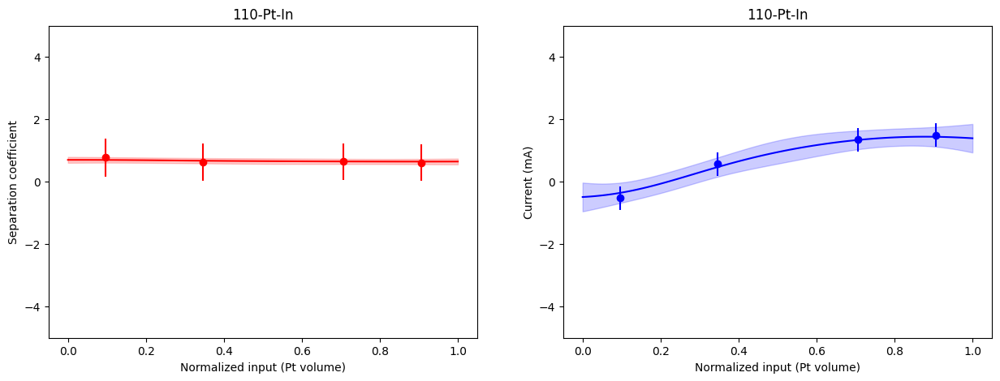

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.0790]), std = tensor([0.0109])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.2103]), std = tensor([0.0009])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


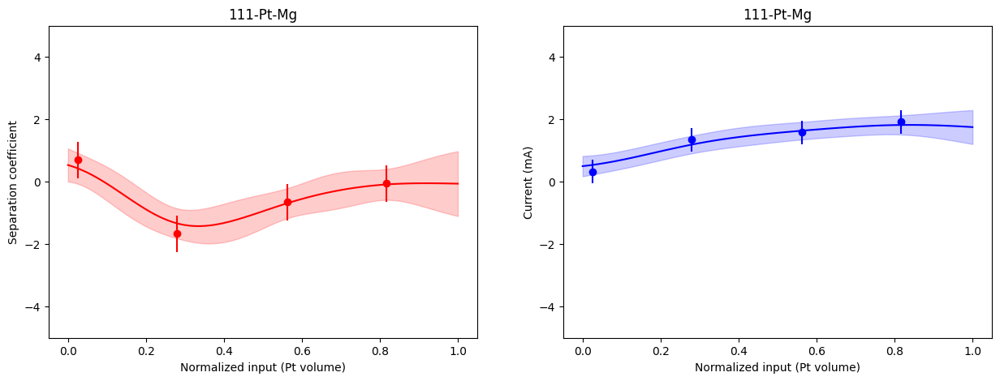

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.3923]), std = tensor([0.0089])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.2115]), std = tensor([0.0003])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


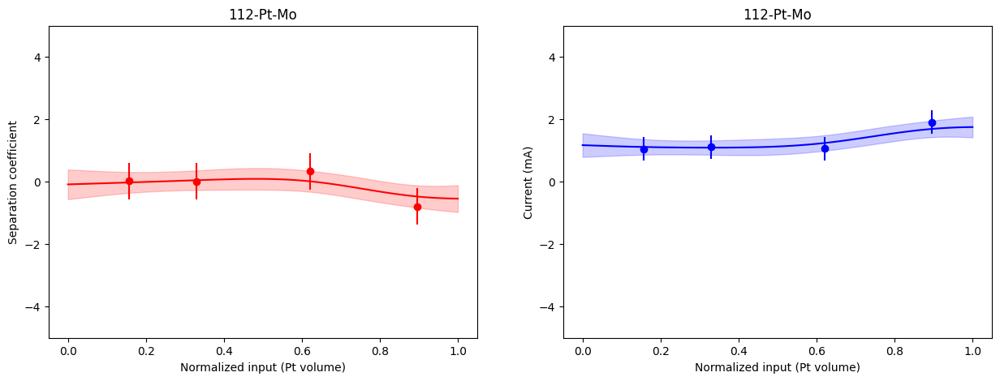

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.2496]), std = tensor([0.0093])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.9516]), std = tensor([0.0014])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


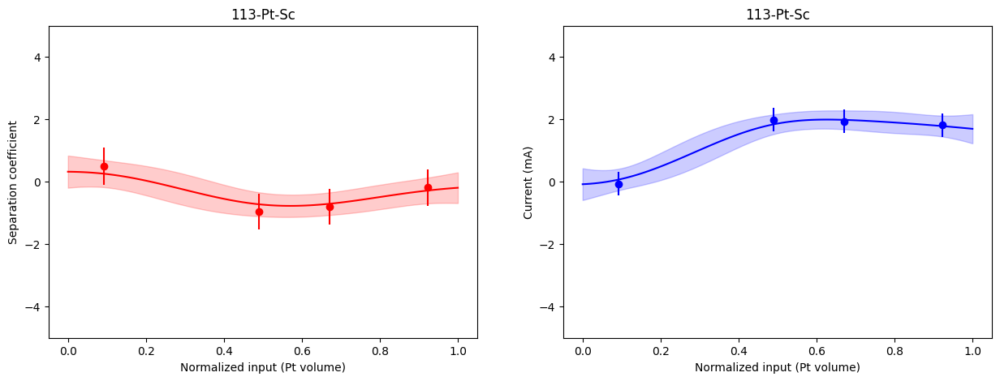

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.3542]), std = tensor([0.0132])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.2250]), std = tensor([0.0017])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


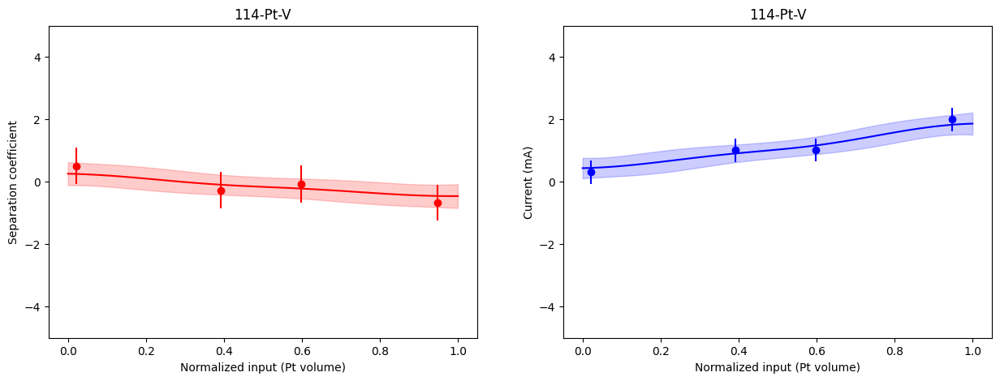

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.8915]), std = tensor([0.0027])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.5727]), std = tensor([0.0005])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


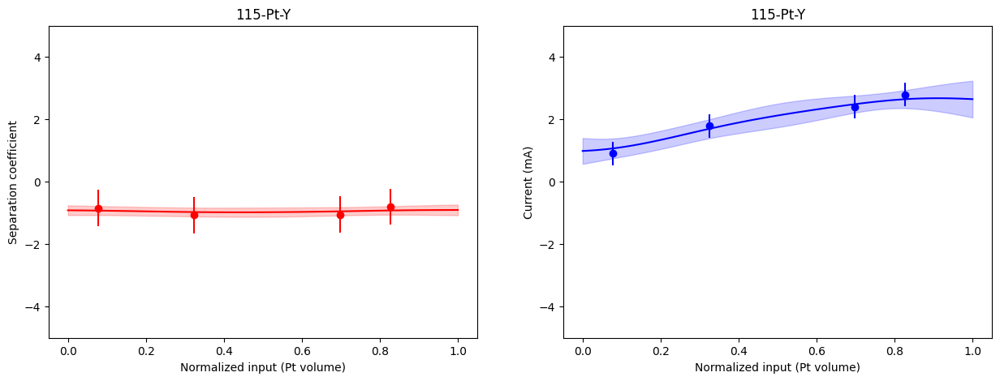

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.6050]), std = tensor([0.0180])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.1518]), std = tensor([0.0005])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


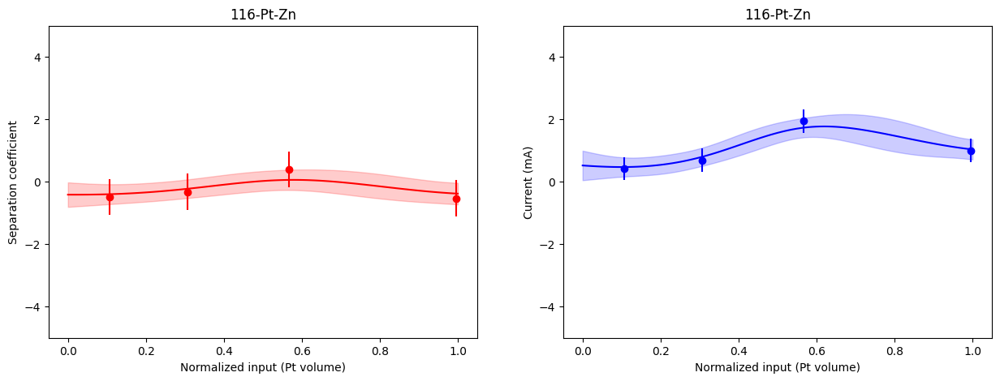

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.8413]), std = tensor([0.3785])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([5.9641]), std = tensor([6.4548e-06])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


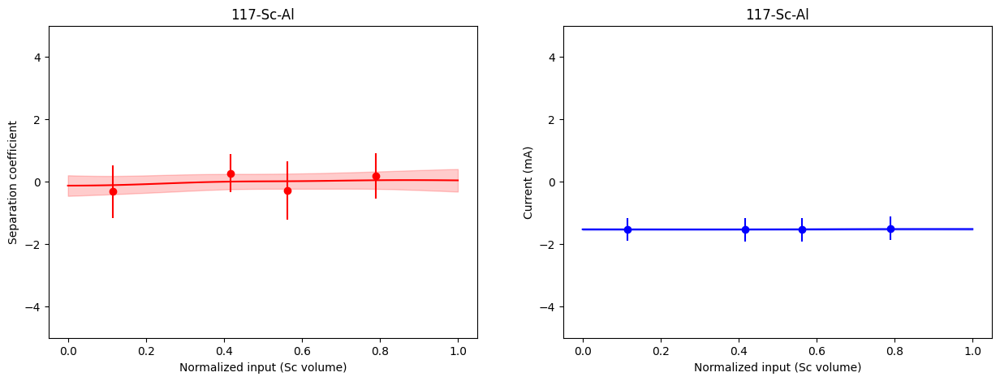

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.3680]), std = tensor([0.0408])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.6851]), std = tensor([3.8463e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


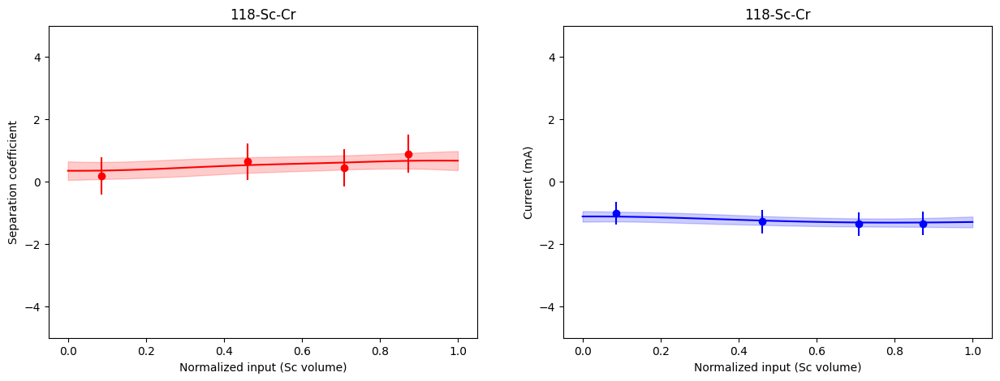

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.2700]), std = tensor([0.7159])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.5990]), std = tensor([1.4325e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


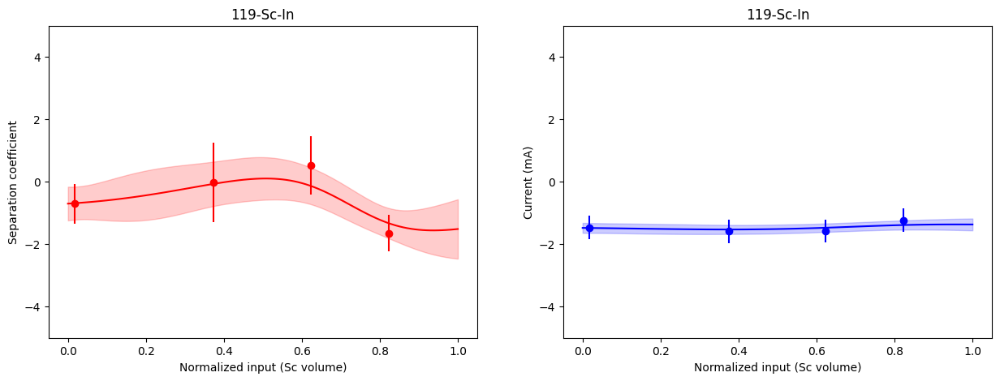

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.5248]), std = tensor([0.1125])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.1854]), std = tensor([1.6471e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


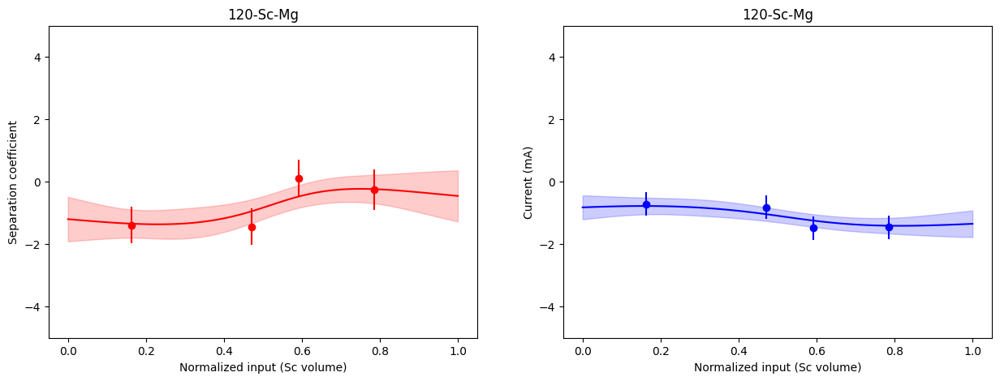

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.1621]), std = tensor([0.0769])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.3613]), std = tensor([5.6227e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


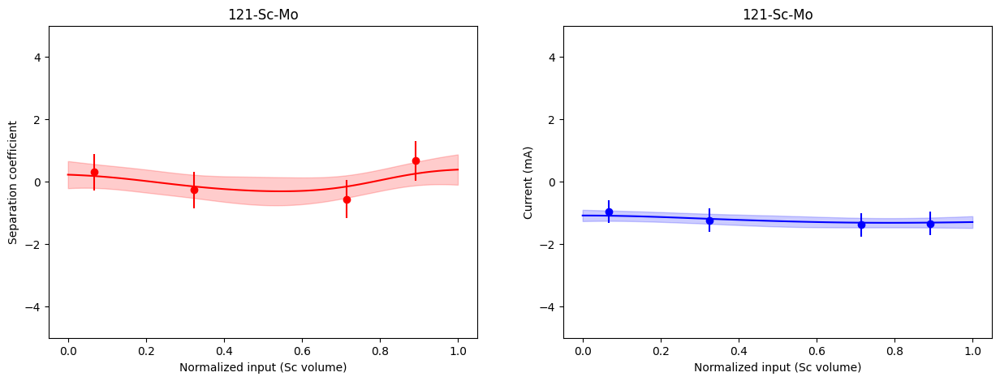

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.2407]), std = tensor([0.1867])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([4.3029]), std = tensor([1.8927e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


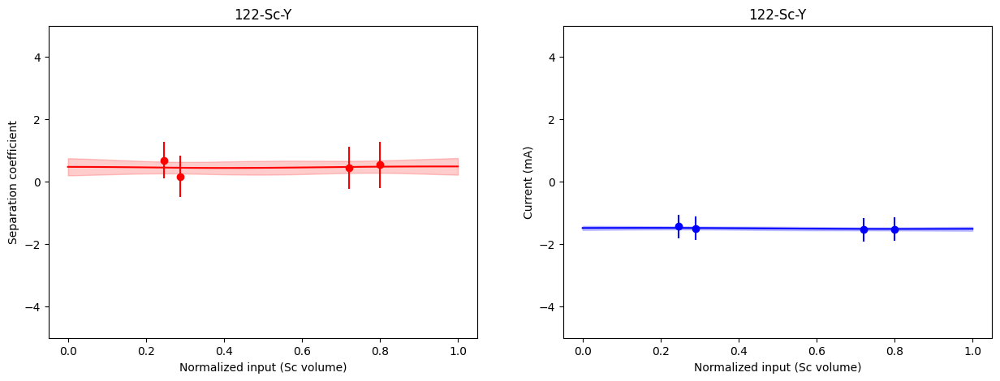

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.7733]), std = tensor([0.0393])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.9960]), std = tensor([4.6382e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


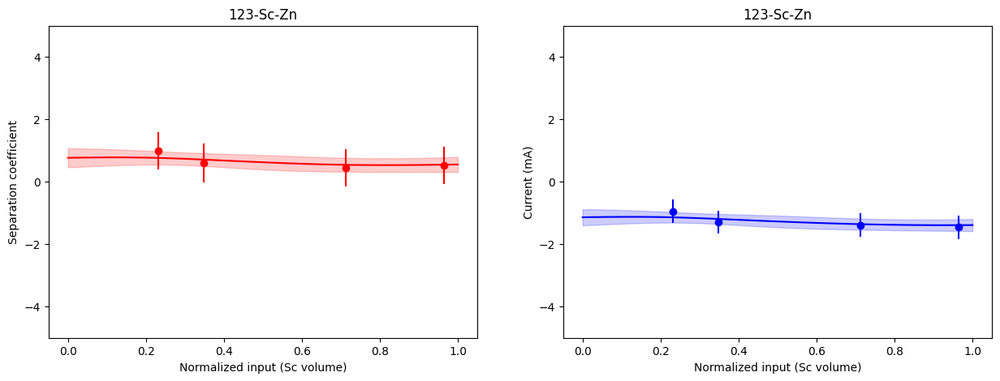

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.2546]), std = tensor([0.0153])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.6295]), std = tensor([0.0001])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


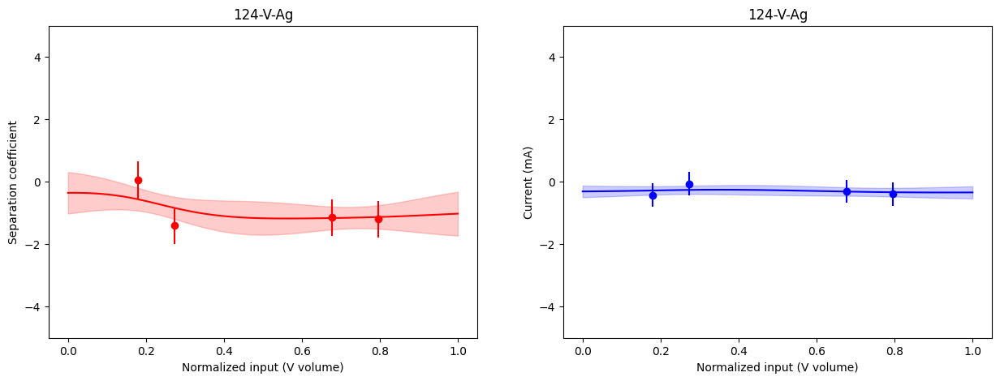

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.9144]), std = tensor([0.0320])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.2846]), std = tensor([0.0002])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


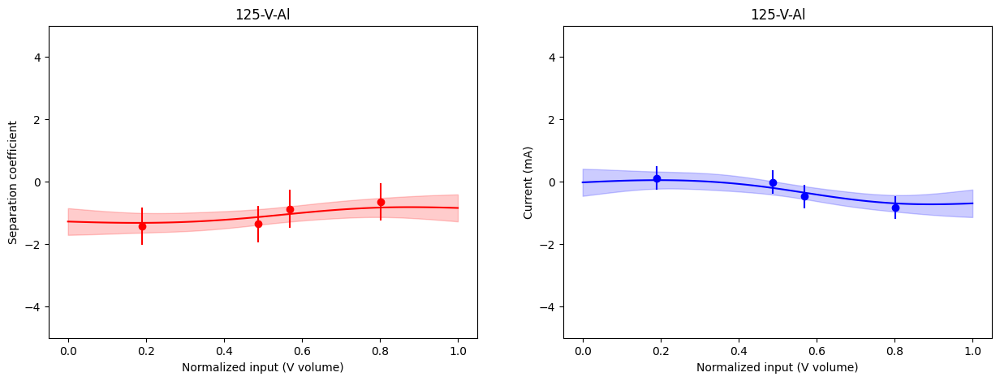

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([3.1804]), std = tensor([0.0359])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.4914]), std = tensor([0.0001])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


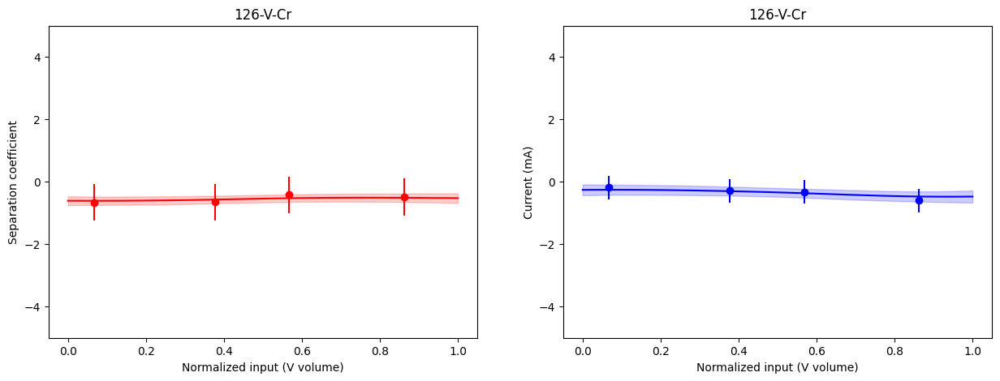

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([4.3160]), std = tensor([0.0310])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([5.4974]), std = tensor([1.5992e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


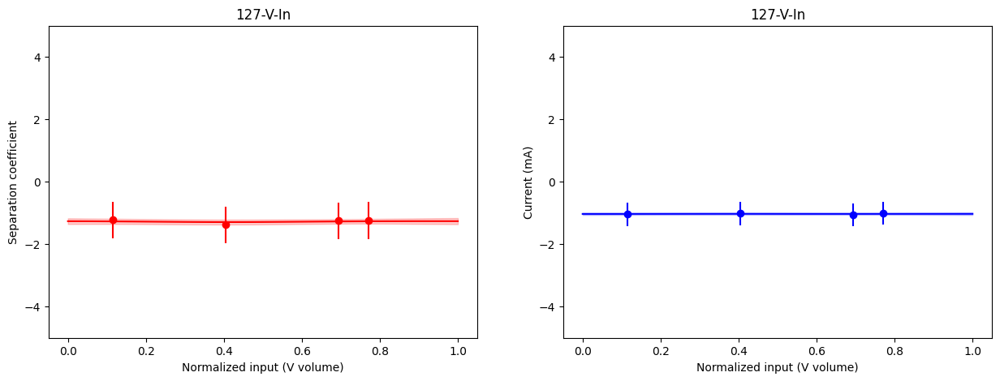

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.7324]), std = tensor([0.0961])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.5593]), std = tensor([0.0003])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


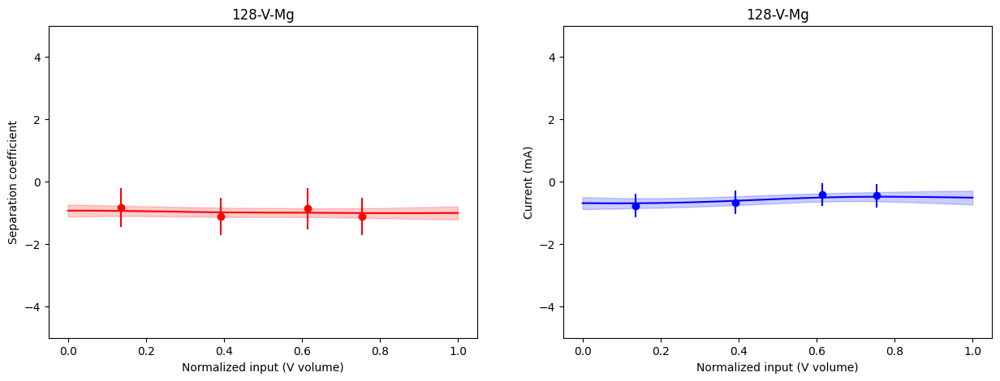

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.2102]), std = tensor([0.0048])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.4721]), std = tensor([2.7793e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


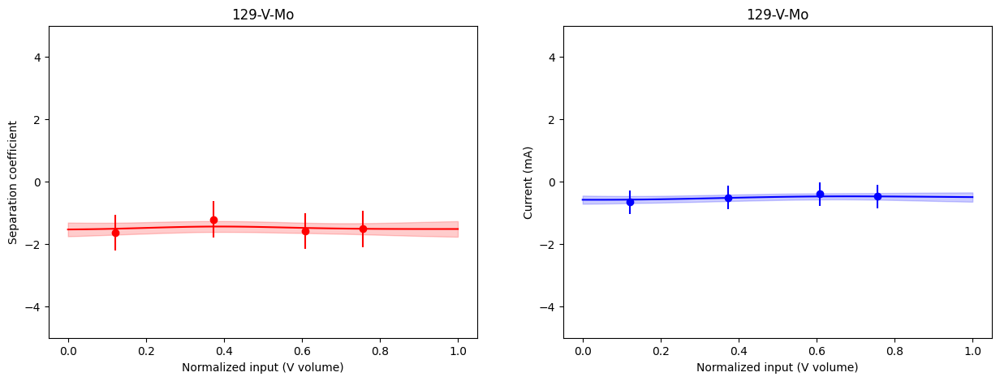

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.7476]), std = tensor([0.0138])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.9808]), std = tensor([9.2714e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


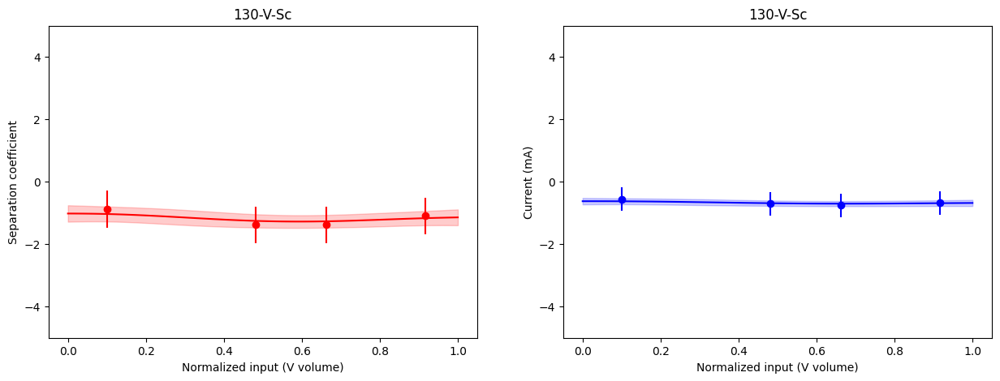

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([3.4456]), std = tensor([0.0074])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.0321]), std = tensor([0.0003])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


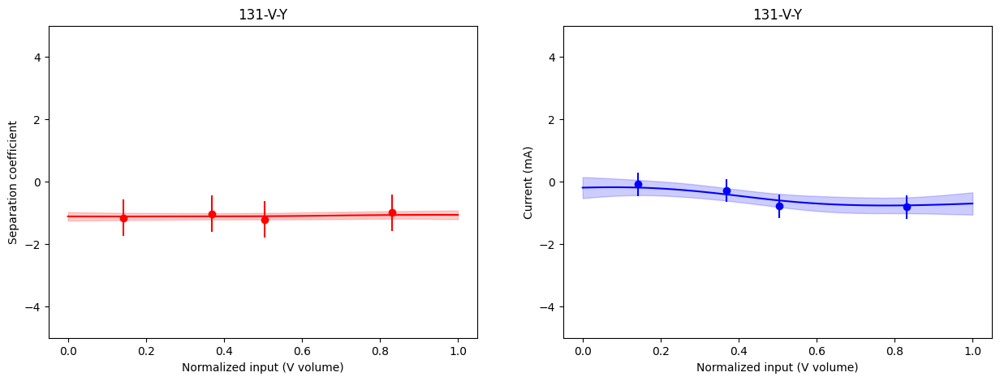

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.9176]), std = tensor([0.0274])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([0.2114]), std = tensor([0.0001])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


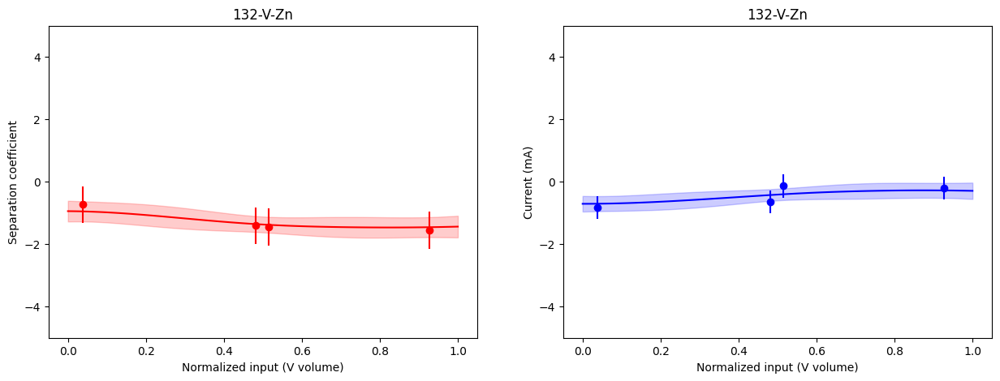

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.5631]), std = tensor([0.0157])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([2.1623]), std = tensor([3.7709e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


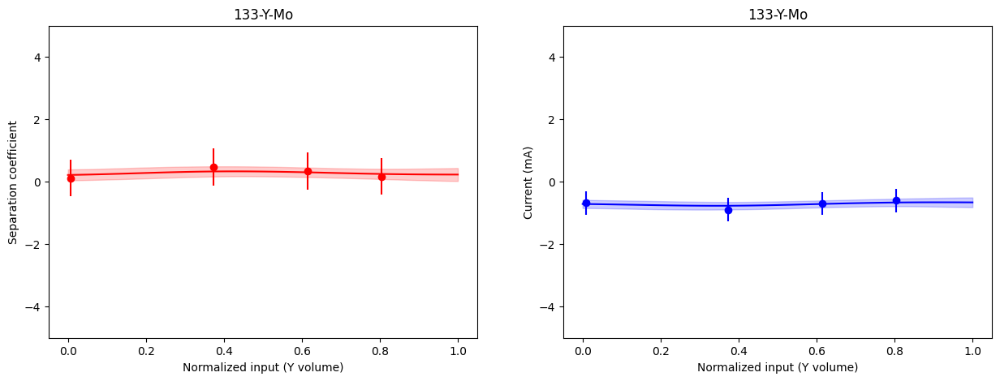

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.2834]), std = tensor([0.0715])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-0.4919]), std = tensor([0.0001])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


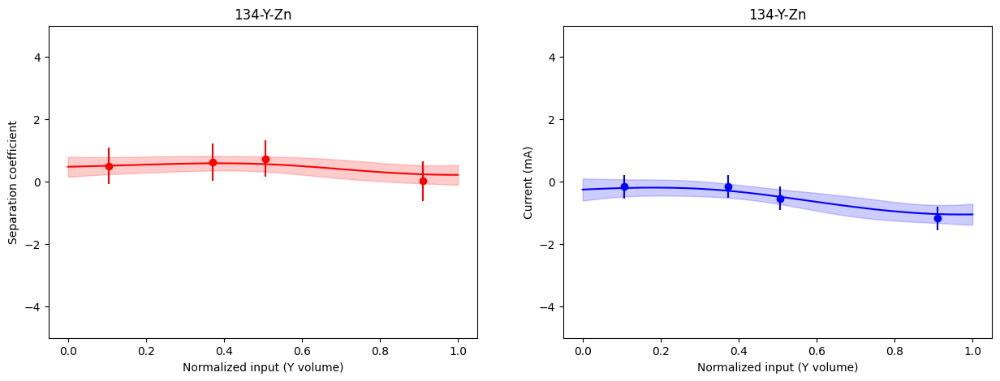

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-1.0944]), std = tensor([0.0354])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([1.4091]), std = tensor([3.2027e-05])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


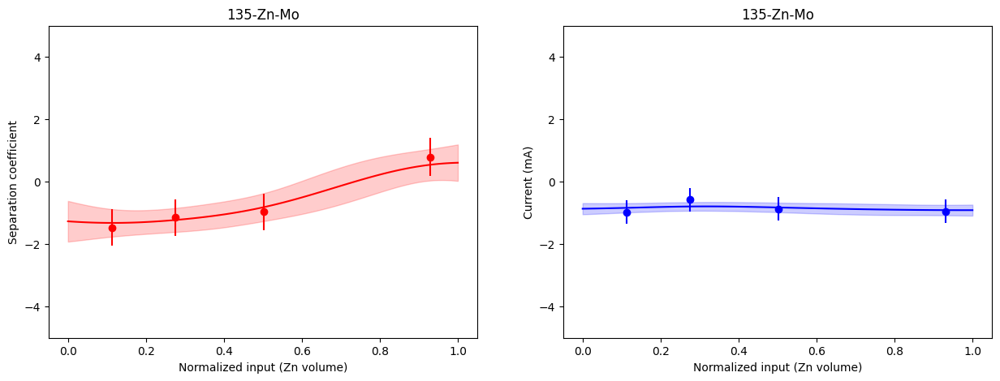

In [6]:
np.random.seed(42)
torch.manual_seed(42)

model_total = {}
y_train_total = []
failures = []


for i in range(len(metal_combo)):
    # get the selected index
    selected_index = np.where((metal_combo_original == metal_combo[i]).all(axis = 1) == True)[0]
    
    # read in the data
    x = []
    y_mean = []
    y_var = []
    y_current_mean = []
    y_current_var = []
    
    # read in the data 
    for j in selected_index:
        x.append((exp_data.iloc[j]["volume1"]/20 - 0.025)/0.95)
        y_mean.append(exp_data.iloc[j]["mean_S"])
        y_var.append(exp_data.iloc[j]["variance_S"])
        y_current_mean.append(exp_data.iloc[j]["mean_current"])
        y_current_var.append(exp_data.iloc[j]["variance_current"])
            
    # process the data input numpy array
    x = np.array(x).reshape(-1,1)
    y_mean = np.array(y_mean).reshape(-1,1)
    y_var = np.array(y_var).reshape(-1,1)
    y_current_mean = np.array(y_current_mean).reshape(-1,1)
    y_current_var = np.array(y_current_var).reshape(-1,1) 
    
    # if the data is not empty, perform machine learning
    if len(x)>0:
        # initialize the machine learning models for 
        train_x = torch.tensor(x).reshape(-1,1)
        train_y = torch.tensor(np.concatenate([y_mean,y_current_mean], axis = 1))
        train_y_var = torch.tensor(np.concatenate([y_var,y_current_var], axis = 1))
        
        # add the data to the whole data set 
        y_train_total.append(train_y)

        # initialize the model 
        mll, model = botorch_tool.tools.initialize_heter_noise_model(train_x = train_x,
                                                                     train_obj = train_y,
                                                                     train_obj_var = train_y_var)
        # fit the model
        try:
            fit_gpytorch_mll(mll)
        except:
            print(f"fitting noiseless model for combination {i}")
            failures.append(i)
            try:
                # initialize the noiseless model (not really noiseless, because the noise is estimated by the means)
                mll, model = botorch_tool.tools.initialize_noiseless_model(train_x = train_x,
                                                                           train_obj = train_y)
                fit_gpytorch_mll(mll)
            except:
                raise ValueError(f"model fitting failed on combination {i}!")
        
        # show the prediction of the machine learning models
        x_plot = torch.tensor(np.linspace(0,1,101))
        preidct = model.posterior(x_plot).mean.detach().numpy()
        std = np.sqrt(model.posterior(x_plot).variance.detach().numpy())
        substance1 = metal_combo[i,0]
        substance2 = metal_combo[i,1]

        # plot the results from the prediction 
        fig, axs = plt.subplots(1, 2, figsize=(15, 5))
        # plot the coefficient of H/D splitting 
        axs[0].plot(x_plot, preidct[:,0], color = "red")
        axs[0].fill_between(x_plot, preidct[:,0] + std[:,0], preidct[:,0] - std[:,0],color='red', alpha=0.2)
        axs[0].scatter(train_x, 
                       train_y[:,0],
                       color = "red")
        axs[0].errorbar(train_x.flatten(), 
                        train_y[:,0].flatten(), 
                        yerr = np.sqrt(train_y_var[:,0].flatten()), 
                        xerr = None,  
                        color = "red",
                        ls='none')
        axs[0].set_xlabel(f"Normalized input ({substance1} volume)")
        axs[0].set_ylabel("Separation coefficient")
        axs[0].set_ylim(-5,5)
        axs[0].set_title(f"{i}-" + substance1 + "-" + substance2)

        # show the plot for the second prediction 
        axs[1].plot(x_plot, preidct[:,1], color = "blue")
        axs[1].fill_between(x_plot, preidct[:,1] + std[:,1], preidct[:,1] - std[:,1], color='blue', alpha=0.2)
        axs[1].scatter(train_x, 
                       train_y[:,1],
                       color = "blue")
        axs[1].errorbar(train_x.flatten(), 
                        train_y[:,1].flatten(), 
                        yerr = np.sqrt(train_y_var[:,1].flatten()), 
                        xerr = None,
                        color = "blue",
                        ls='none')
        
        axs[1].set_xlabel(f"Normalized input ({substance1} volume)")
        axs[1].set_ylabel("Current (mA)")
        axs[1].set_ylim(-5, 5)

        axs[1].set_title(f"{i}-" + substance1 + "-" + substance2)
        
        # show the plot for the fitness function 
        
        plt.show()
        plt.close()
        
        # append the model to the total model list 
        model_total[f"{i}-" + substance1 + "-" + substance2] = model
    else:
        raise ValueError(i)

### design the new experiments

In [7]:
np.random.seed(42)
torch.manual_seed(42)

# get total observations
obs_total = torch.concat(y_train_total, axis = 0)
# get the reference poitn
ref_point = [obs_total[:,0].min().numpy().item(), 
             obs_total[:,1].min().numpy().item()]

# get the bounds for the optimization 
bounds = torch.stack([torch.zeros(1), torch.ones(1)])
candidate_total = {}

# get the candidate for each model 
for model_key, model_val in model_total.items():
    MC_SAMPLES = 1024
    sampler = SobolQMCNormalSampler(sample_shape=torch.Size([MC_SAMPLES]))
    candidate, expected_y = botorch_tool.tools.optimize_qehvi_and_get_observation_obs(
        model = model_val, 
        obs = obs_total, 
        standard_bounds = bounds, 
        sampler = sampler, 
        ref_point = ref_point)
    candidate_total[model_key] = [candidate, expected_y]
    
    print(f"{model_key}: {candidate} {expected_y}")

/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/optim/initializers.py:432: BadInitialCandidatesWarning: Unable to find non-zero acquisition function values - initial conditions are being selected randomly.
  warnings.warn(


0-Ag-Al: tensor([[0.2331]]) 0.0


/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/optim/initializers.py:432: BadInitialCandidatesWarning: Unable to find non-zero acquisition function values - initial conditions are being selected randomly.
  warnings.warn(


1-Ag-Cr: tensor([[0.1095]]) 0.0


/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/optim/initializers.py:432: BadInitialCandidatesWarning: Unable to find non-zero acquisition function values - initial conditions are being selected randomly.
  warnings.warn(


2-Ag-In: tensor([[0.4142]]) 0.0


... (161 outputs left out)

133-Y-Mo: tensor([[0.6216]]) 0.0


/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/optim/initializers.py:432: BadInitialCandidatesWarning: Unable to find non-zero acquisition function values - initial conditions are being selected randomly.
  warnings.warn(


134-Y-Zn: tensor([[0.2980]]) 0.0
135-Zn-Mo: tensor([[0.3049]]) 0.0


/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/optim/initializers.py:432: BadInitialCandidatesWarning: Unable to find non-zero acquisition function values - initial conditions are being selected randomly.
  warnings.warn(


In [8]:
# get all the candidates
systems = np.array(list(candidate_total.keys()))
conditions = np.array(torch.tensor(list(candidate_total.values())))
# sort them according to the improvement, and select the top 16 candidates
seleceted_conditions = conditions[np.argsort(conditions[:,1])[::-1]][0:16]
seleceted_systems = systems[np.argsort(conditions[:,1])[::-1]][0:16]

In [9]:
# write the new candidates to the excel for the closed-loop discovery 
exp_data_out = {}
exp_data_out["substance1"] = []
exp_data_out["volume1"] = []
exp_data_out["substance2"] =[]
exp_data_out["volume2"] = []

exp_data_out["voltage"] = []

exp_data_out["syn_completed"] = []
exp_data_out["storage_location"] = []
exp_data_out["in_storage"] = []

exp_data_out["mass_file_name"] = []
exp_data_out["mass_time"] = []
exp_data_out["cat_completed"] = []

exp_data_out = pd.DataFrame(exp_data_out)

for i in range(len(seleceted_conditions)):
    systemn_tmp = seleceted_systems[i].split("-")
    substance1 = systemn_tmp[1]
    substance2 = systemn_tmp[2]
    volume1 = (seleceted_conditions[i][0]*0.95 + 0.025)*20
    volume2 = 20 - volume1
    volume1 = np.around(volume1, 2)
    volume2 = np.around(volume2, 2)

    temp = pd.DataFrame({"substance1":[substance1], 
                         "volume1":[volume1], 
                         "substance2":[substance2], 
                         "volume2":[volume2],
                         "voltage": ["None"],
                         "syn_completed": ["None"],
                         "storage_location": ["None"],
                         "in_storage": ["None"],
                         "mass_file_name": ["None"],
                         "mass_time": ["None"],
                         "cat_completed": ["None"]})
    exp_data_out = pd.concat((exp_data_out,temp),ignore_index=True)
    
# write to the file 
# exp_data_out.to_json(f"./all_experiment_{BATCH_NUM+1}_to_do.json")

In [10]:
seleceted_conditions

array([[0.        , 0.49157295],
       [1.        , 0.19397065],
       [0.        , 0.1918211 ],
       [1.        , 0.13060896],
       [1.        , 0.07567514],
       [1.        , 0.07540369],
       [1.        , 0.07381676],
       [0.99741857, 0.07331723],
       [1.        , 0.06445829],
       [1.        , 0.06295256],
       [1.        , 0.05786921],
       [1.        , 0.04780613],
       [1.        , 0.04571385],
       [0.58671632, 0.04096325],
       [0.64611482, 0.03708432],
       [1.        , 0.02962431]])

In [11]:
seleceted_systems

array(['19-Cd-Pt', '98-Ni-Cr', '97-Ni-Cd', '115-Pt-Y', '33-Co-Ni',
       '104-Ni-V', '26-Co-Cd', '65-Fe-Mo', '31-Co-Mn', '67-Fe-Pt',
       '25-Co-Al', '48-Cu-Mn', '111-Pt-Mg', '44-Cu-Cd', '109-Pt-Cr',
       '101-Ni-Mo'], dtype='<U9')

### plot the results for the current batch 

#### Paereto Front

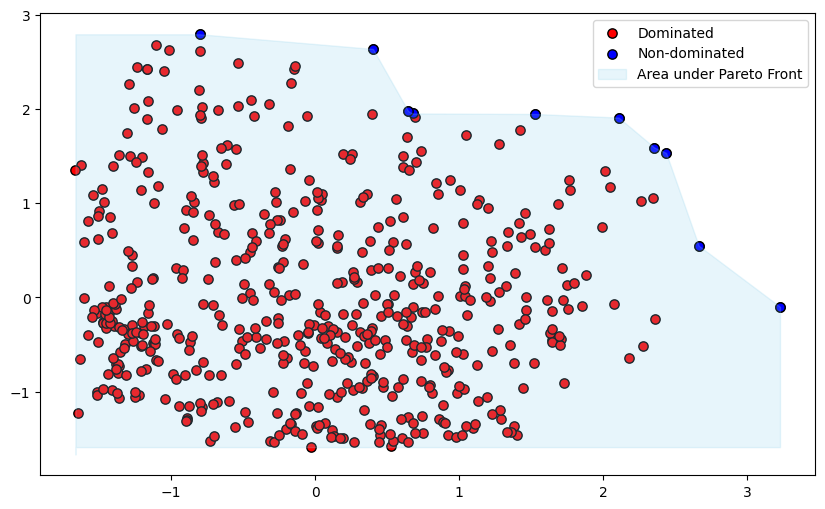

In [12]:
# define a partiton to compute the hypervolume now 
from botorch.utils.multi_objective.box_decompositions.non_dominated import FastNondominatedPartitioning
from botorch.utils.multi_objective.pareto import is_non_dominated

# check if something is non-dominated
pareto_mask = is_non_dominated(obs_total)

# get the non-dominated data 
pareto_Y = obs_total[pareto_mask]
x_prf = pareto_Y[:,0]
y_prf = pareto_Y[:,1]

partitioning = FastNondominatedPartitioning(
    ref_point = torch.tensor(ref_point),
    Y = obs_total
)
partitioning._compute_hypervolume_if_y_has_data()

# show the current results 
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(obs_total[:,0], obs_total[:,1], color = "red", linewidths=1, edgecolors = "black", s=45, label = "Dominated")
ax.scatter(pareto_Y[:,0], pareto_Y[:,1], color = "blue", linewidths=1, edgecolors = "black", s=45, label = "Non-dominated")

sorted_indices = np.argsort(x_prf)
x_sorted = x_prf[sorted_indices].numpy()
y_sorted = y_prf[sorted_indices].numpy()

ax.fill_between(np.insert(x_sorted, [0, 0], [ref_point[0], ref_point[0]]), 
                np.ones(len(x_sorted)+2)*ref_point[1],
                np.insert(y_sorted, [0, 0], [ref_point[0], y_sorted.max()]), 
                color='skyblue', 
                alpha=0.2, label='Area under Pareto Front')
ax.legend()

In [13]:
exp_data.values[pareto_mask]

array([['Cd', 'Pt', 1.81, 18.19, 0.4019399678555576, 0.3431689157738899,
        2.636884537363259, 0.14010414762123452],
       ['Co', 'Ag', 13.01, 6.99, 2.3570853116289556, 0.34559771163464226,
        1.5904731381086155, 0.1402047678898811],
       ['Co', 'Al', 19.5, 0.5, 2.438273006217704, 0.5559565842379683,
        1.5339277194977672, 0.14001741934004142],
       ['Co', 'Mn', 18.74, 1.26, 1.5296203920090015, 0.34358434771319446,
        1.9466760524355569, 0.14065545790738102],
       ['Co', 'Ni', 16.09, 3.91, 0.6768385327785004, 0.4313725509257263,
        1.952501138646959, 0.13979788636337692],
       ['Co', 'Pt', 7.52, 12.48, 0.6464472835363706, 0.3464430073168481,
        1.977515786426095, 0.13996914332768084],
       ['Cu', 'Cd', 13.54, 6.46, 3.229482176356177, 0.38185607445279257,
        -0.09881958176155027, 0.1397953834289258],
       ['Cu', 'Mn', 19.18, 0.82, 2.6649191985308534, 0.3593480681783805,
        0.5492560324604512, 0.13981254938868817],
       ['Ni', 'Cd', 

#### prediction and acquisition

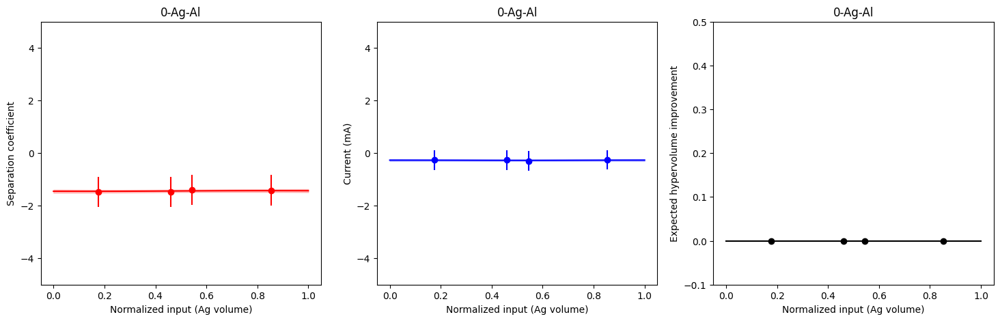

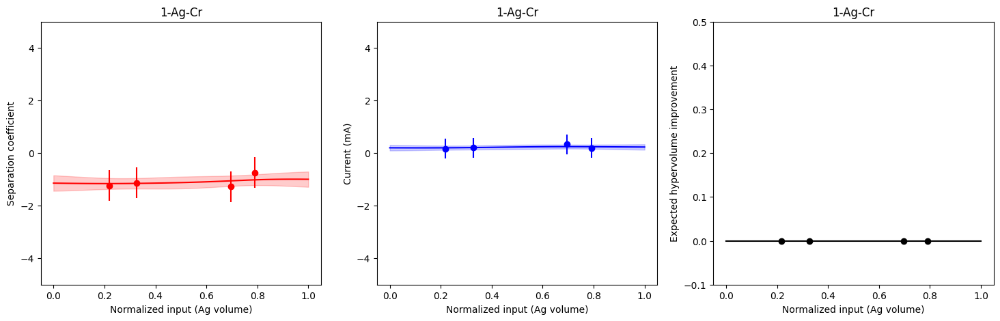

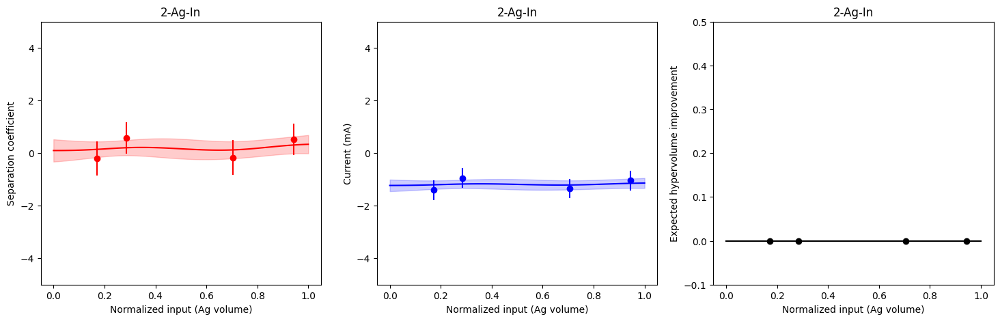

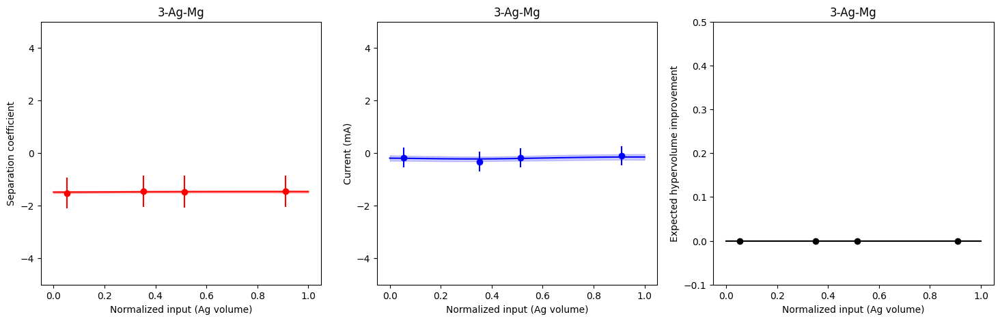

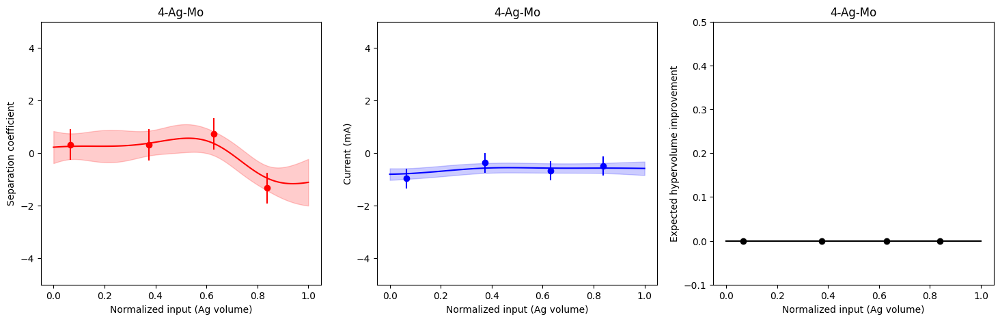

...

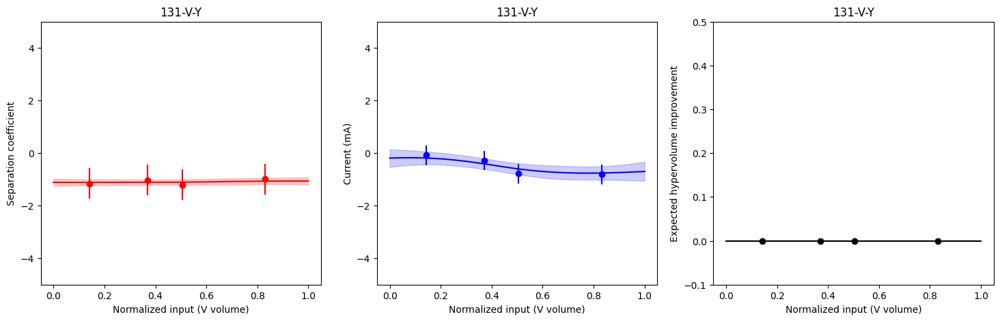

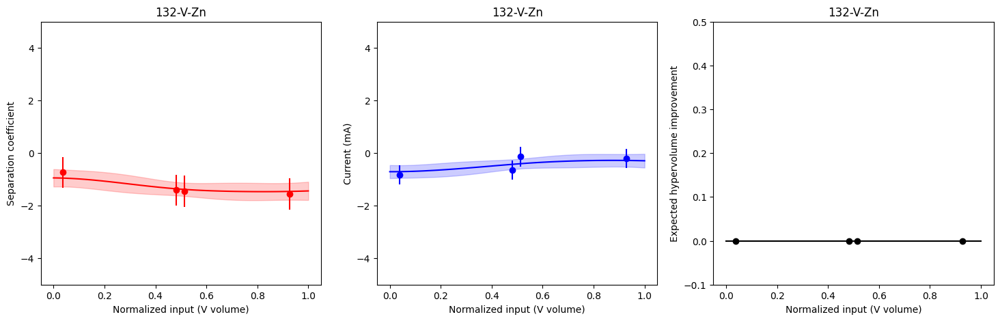

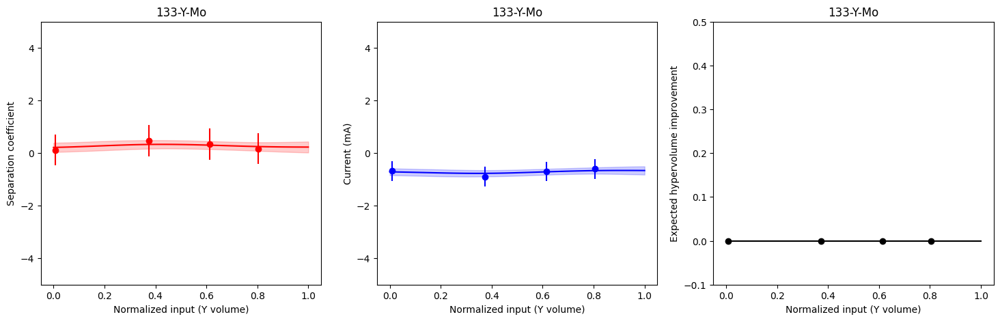

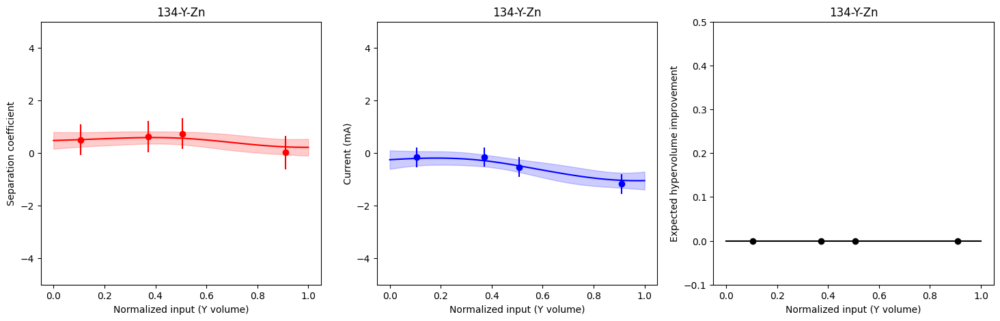

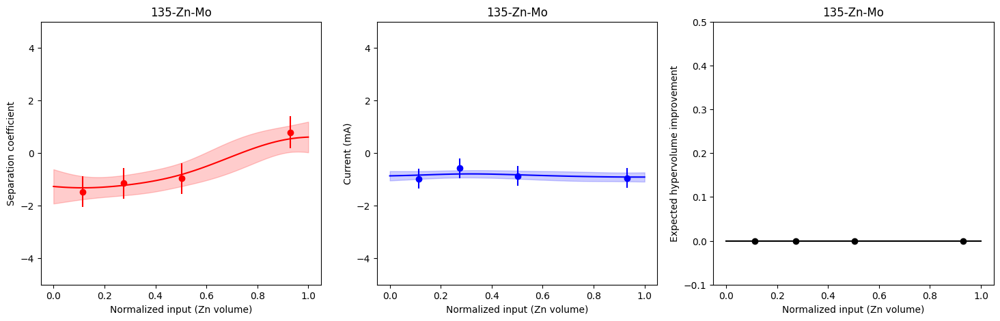

In [14]:
# plot the prediction of two objects, as well as the value of the acquisition functions 
from botorch.acquisition.multi_objective.monte_carlo import qExpectedHypervolumeImprovement

np.random.seed(42)
torch.manual_seed(42)

for i in range(len(metal_combo)):
    # get the selected index
    selected_index = np.where((metal_combo_original == metal_combo[i]).all(axis = 1) == True)[0]
    
    # read in the data
    x = []
    y_mean = []
    y_var = []
    y_current_mean = []
    y_current_var = []
    
    # read in the data 
    for j in selected_index:
        x.append((exp_data.iloc[j]["volume1"]/20 - 0.025)/0.95)
        y_mean.append(exp_data.iloc[j]["mean_S"])
        y_var.append(exp_data.iloc[j]["variance_S"])
        y_current_mean.append(exp_data.iloc[j]["mean_current"])
        y_current_var.append(exp_data.iloc[j]["variance_current"])
            
    # process the data input numpy array
    x = np.array(x).reshape(-1,1)
    y_mean = np.array(y_mean).reshape(-1,1)
    y_var = np.array(y_var).reshape(-1,1)
    y_current_mean = np.array(y_current_mean).reshape(-1,1)
    y_current_var = np.array(y_current_var).reshape(-1,1) 
    
    # if the data is not empty, perform machine learning
    if len(x)>0:
        # initialize the machine learning models for 
        train_x = torch.tensor(x).reshape(-1,1)
        train_y = torch.tensor(np.concatenate([y_mean,y_current_mean], axis = 1))
        train_y_var = torch.tensor(np.concatenate([y_var,y_current_var], axis = 1))

        # model 
        substance1 = metal_combo[i,0]
        substance2 = metal_combo[i,1]
        model = model_total[f"{i}-" + substance1 + "-" + substance2]
        
        # show the prediction of the machine learning models
        x_plot = torch.tensor(np.linspace(0,1,101))
        preidct = model.posterior(x_plot).mean.detach().numpy()
        std = np.sqrt(model.posterior(x_plot).variance.detach().numpy())

        # plot the results from the prediction 
        fig, axs = plt.subplots(1, 3, figsize=(18, 5))
        # plot the coefficient of H/D splitting 
        axs[0].plot(x_plot, preidct[:,0], color = "red")
        axs[0].fill_between(x_plot, preidct[:,0] + std[:,0], preidct[:,0] - std[:,0],color='red', alpha=0.2)
        axs[0].scatter(train_x, 
                       train_y[:,0],
                       color = "red")
        axs[0].errorbar(train_x.flatten(), 
                        train_y[:,0].flatten(), 
                        yerr = np.sqrt(train_y_var[:,0].flatten()), 
                        xerr = None,  
                        color = "red",
                        ls='none')
        axs[0].set_xlabel(f"Normalized input ({substance1} volume)")
        axs[0].set_ylabel("Separation coefficient")
        axs[0].set_ylim(-5,5)
        axs[0].set_title(f"{i}-" + substance1 + "-" + substance2)

        # show the plot for the second prediction 
        axs[1].plot(x_plot, preidct[:,1], color = "blue")
        axs[1].fill_between(x_plot, preidct[:,1] + std[:,1], preidct[:,1] - std[:,1], color='blue', alpha=0.2)
        axs[1].scatter(train_x, 
                       train_y[:,1],
                       color = "blue")
        axs[1].errorbar(train_x.flatten(), 
                        train_y[:,1].flatten(), 
                        yerr = np.sqrt(train_y_var[:,1].flatten()), 
                        xerr = None,
                        color = "blue",
                        ls='none')
        
        axs[1].set_xlabel(f"Normalized input ({substance1} volume)")
        axs[1].set_ylabel("Current (mA)")
        axs[1].set_ylim(-5, 5)

        axs[1].set_title(f"{i}-" + substance1 + "-" + substance2)
        
        # show the plot for the fitness function 
        MC_SAMPLES = 1024
        sampler = SobolQMCNormalSampler(sample_shape=torch.Size([MC_SAMPLES]))
        acq_func = qExpectedHypervolumeImprovement(
            model=model,
            ref_point=ref_point,
            partitioning=partitioning,
            sampler=sampler
        )
        acq_values = acq_func(x_plot.reshape(-1, 1, 1)).detach().numpy().flatten()
        # show the plot for the second prediction 
        axs[2].plot(x_plot, acq_values, color = "black")
        axs[2].scatter(train_x, 
                       acq_func(train_x.reshape(-1,1,1)).detach().numpy().flatten(),
                       color = "black")
        
        axs[2].set_xlabel(f"Normalized input ({substance1} volume)")
        axs[2].set_ylabel("Expected hypervolume improvement")
        axs[2].set_ylim(-0.1, 0.5)
        axs[2].set_title(f"{i}-" + substance1 + "-" + substance2)
        
        plt.show()
        plt.close()
        
    else:
        raise ValueError(i)